# Fintech Loan Portfolio: From Data to Credit Decisions

**Introduction**

In this project I evaluate the health of a fintech's personal loan portfolio. The goal is to support **credit decisions with data**: who to approve, how to price, where to verify and where collections should focus.

The data sits in three BigQuery tables (project `fintech-510922`):

- **loan** → 270,299 loans issued between 2012 and 2019, with amount, interest rate, term, installment, risk grade, purpose and current status
- **customer** → one row per borrower: annual income, joint income, employment length, home ownership, income verification and existing debt
- **state_region** → US states with their subregion and region

The analysis moves in this order, and each stage builds on the one before:

1. 🔍 Check whether the data can be trusted (exploration in Python, quality checks in SQL)
2. 🛠️ Turn the raw tables into a clean relational model (SQL in BigQuery)
3. 💰 Measure how much the portfolio earns and loses (KPIs)
4. 🎯 Find the segments that concentrate the risk, and test which signals are real and hold within the same grade
5. ✅ Simulate an approval rule
6. 📈 Look at growth, quality by vintage and collections priorities
7. 📊 Share the results (Looker dashboard)

**Business questions**

| Objective | Question | KPI |
|---|---|---|
| Reduce losses | P1. How much do we lend, how much defaults and how much do we lose? | K1 |
| Reduce losses | P2. Which customer profile defaults the most? | K3 |
| Reduce losses | P3. Which approval rule would reduce losses without giving up too much interest? | K5 |
| Increase revenue | P4. Does the interest rate of each grade and term pay for its risk? | K2 |
| Increase revenue | P5. Is the portfolio growing while keeping its quality? | K6 |
| Reduce costs | P6. Does verifying income reduce default within the same grade? | K4 |
| Reduce costs | P7. Where is the money in delinquency concentrated? | K7 |
| Reduce losses | P8. Which variables are really associated with default, and do they hold within the same grade? | K8 |

**How I split the work:** the raw data stays in BigQuery (`fintech_raw`). Python is where I explore and diagnose. The final transformation is written **once, in SQL**, and every KPI is calculated in BigQuery. I only go back to Python when it does something SQL can't: quick exploration, statistical tests and charts.

---

## 🔹 Step 1: Load and Explore the Data (Python)

---

### 1.1 Data Loading and Quick Overview

**🎯 My objective:** Get to know the three tables and find every issue that could distort the analysis, before deciding how to clean anything.

**Why Python and not SQL here:** exploring means trying one idea after another (a count, a crosstab, a boxplot), and pandas is faster for that. At this stage Python only **diagnoses**. Every correction is written once, in SQL (Step 3), so there's a single version of the clean data and no rule gets applied twice.

**What I do:**

- Import the libraries and connect to BigQuery
- Load the three CSV files, upload them to BigQuery (`fintech_raw`) and keep them as DataFrames: `loan`, `customer`, `state_region`
- Build reusable diagnostic functions
- Explore each dataset and write down every issue with its evidence

---

💡 In RappiPlus I connected to PostgreSQL with `create_engine` and read with `pd.read_sql`. Here the connection goes to BigQuery: I create a `client` for the project and a `consultar` function that plays the role of `pd.read_sql`. It takes a SQL query and returns a DataFrame.

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.cloud import bigquery
from scipy.stats import chi2_contingency, pointbiserialr   # prueba chi-cuadrado entre variables categóricas y correlación punto-biserial (binaria vs numérica)
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep   # prueba z de proporciones y su intervalo de confianza

# conexión a BigQuery
PROJECT = 'fintech-510922'
client = bigquery.Client(project=PROJECT, location='US')

def consultar(query): # Envía una query a BigQuery y devuelve el resultado como DataFrame
    return client.query(query).to_dataframe()

💡 `cargar_csv` reads each CSV with pandas and uploads it to BigQuery as a new table in `fintech_raw` (`WRITE_TRUNCATE` replaces it if it already exists). Going through pandas keeps the real column names from the CSV header. When I loaded `state_region` from the BigQuery console, they had turned into `string_field_0`, `string_field_1` and `string_field_2`. The function also returns the DataFrame, so the same step leaves the data ready to explore in Python.

In [2]:
# cargar archivos: se leen los CSV y se suben a BigQuery (dataset fintech_raw)
def cargar_csv(ruta, tabla): # Lee un CSV, lo sube a BigQuery como tabla nueva y devuelve el DataFrame
    df = pd.read_csv(ruta) # se lee el CSV; la primera fila se toma como nombres de columna
    destino = f'{PROJECT}.fintech_raw.{tabla}' # nombre completo de la tabla: proyecto.dataset.tabla
    config = bigquery.LoadJobConfig(write_disposition='WRITE_TRUNCATE') # si la tabla existe, se reemplaza
    trabajo = client.load_table_from_dataframe(df, destino, job_config=config) # se envía la carga
    trabajo.result() # se espera a que termine
    print(f'Tabla {destino} cargada')
    return df

loan = cargar_csv('../data/raw/loan.csv', 'loan')
customer = cargar_csv('../data/raw/customer.csv', 'customer')
state_region = cargar_csv('../data/raw/state_region.csv', 'state_region')


c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\_pandas_helpers.py:486: FutureWarning: Loading pandas DataFrame into BigQuery will require pandas-gbq package version 0.26.1 or greater in the future. Tried to import pandas-gbq and got: No module named 'pandas_gbq'
  warnings.warn(


Tabla fintech-510922.fintech_raw.loan cargada


c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\_pandas_helpers.py:486: FutureWarning: Loading pandas DataFrame into BigQuery will require pandas-gbq package version 0.26.1 or greater in the future. Tried to import pandas-gbq and got: No module named 'pandas_gbq'
  warnings.warn(


Tabla fintech-510922.fintech_raw.customer cargada


c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\_pandas_helpers.py:486: FutureWarning: Loading pandas DataFrame into BigQuery will require pandas-gbq package version 0.26.1 or greater in the future. Tried to import pandas-gbq and got: No module named 'pandas_gbq'
  warnings.warn(


Tabla fintech-510922.fintech_raw.state_region cargada


💡 Before exploring, I build the diagnostic functions I'll reuse on the three datasets, with the same logic as in RappiPlus. None of them changes the data. They only describe it.

- `explorar_datos`: the first diagnostic in one call. Size, duplicates, numeric statistics and a summary per column (type, nulls, % nulls, distinct values and a real example).
- `revisar_categoricas`: each category with its count and percentage, nulls included (`dropna=False`), to catch the same category written in different ways.
- `revisar_integridad`: counts the records in a child table whose key doesn't exist in the parent table. Those orphans would be lost in a join.
- `detectar_outliers`: the IQR method (values more than 1.5 × IQR beyond Q1 or Q3), with a boxplot.
- `calcular_pct`: the percentage the other functions use. If the total is zero it returns NaN instead of an error, like `SAFE_DIVIDE` in SQL.

In [3]:
def calcular_pct(cantidad, total): # Calcula porcentajes; devuelve NaN si el total es cero o nulo, como SAFE_DIVIDE en SQL
    if pd.isna(total) or total == 0:
        return np.nan
    return round(cantidad / total * 100, 2)

# exploración de datasets
def explorar_datos(df, nombre): # Diagnóstico inicial: tamaño, duplicados, estadísticas y resumen por columna
    total_filas = len(df)
    if total_filas == 0:
        print(f'{nombre}: el dataframe está vacío (0 filas)')
        return
    duplicados = df.duplicated().sum()
    print(f'--- Dataset: {nombre} ---')
    print(f'{total_filas} filas, {len(df.columns)} columnas')
    print(f'Filas duplicadas: {duplicados} ({calcular_pct(duplicados, total_filas)}%)')
    print('\nEstadísticas de columnas numéricas:')
    print(df.describe())

    resumen = pd.DataFrame({
        'tipo': df.dtypes,
        'nulos': df.isnull().sum(),
        '% nulos': calcular_pct(df.isnull().sum(), total_filas),
        'valores_distintos': df.nunique(),
        'ejemplo': df.bfill().iloc[0]
    })
    return resumen

def revisar_categoricas(df, columnas): # Muestra las categorías, sus cantidades y porcentajes sobre el total
    for col in columnas:
        conteo = df[col].value_counts(dropna=False)
        porcentaje = df[col].value_counts(normalize=True, dropna=False) * 100
        resumen = pd.DataFrame({'total': conteo, '%': porcentaje.round(2)})
        print(f'{col}: \n {resumen} \n')

def revisar_integridad(df_hijo, df_padre, columna): # Cuenta los registros de df_hijo cuya llave no existe en df_padre
    existe = df_hijo[columna].isin(df_padre[columna]) # True si la llave existe en df_padre
    huerfanos = len(df_hijo) - existe.sum() # total de registros menos los que sí existen
    print(f'{columna}: {huerfanos} registros sin pareja ({calcular_pct(huerfanos, len(df_hijo))}%)')

def detectar_outliers(df, columna): #Calcula los límites de valores atípicos con el método IQR, cuenta cuántos hay y los grafica.
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)]
    cantidad = len(outliers)
    pct = calcular_pct(cantidad, len(df))

    print(f'{columna}: registros atipicos: {cantidad} - {pct}%')  # límites y cantidad de atípicos

    plt.figure(figsize=(6, 4))
    sns.boxplot(y=df[columna])
    plt.title('Boxplot atipicos')
    plt.tight_layout()
    plt.show()

    return outliers


💡 `explorar_datos` is my first quality filter. I need to know how healthy each dataset is before deciding how to clean it. I start with `loan`, the central table.

In [4]:
explorar_datos(loan, 'loan')

--- Dataset: loan ---
270299 filas, 18 columnas
Filas duplicadas: 0 (0.0%)

Estadísticas de columnas numéricas:
             loan_id    loan_amount  funded_amount       int_rate  \
count  270299.000000  270299.000000  270299.000000  270299.000000   
mean   135150.000000   15412.829496   15412.829496       0.130765   
std     78028.744543    9459.781419    9459.781419       0.048865   
min         1.000000    1000.000000    1000.000000       0.053100   
25%     67575.500000    8000.000000    8000.000000       0.094300   
50%    135150.000000   13200.000000   13200.000000       0.126100   
75%    202724.500000   20300.000000   20300.000000       0.160100   
max    270299.000000   40000.000000   40000.000000       0.309900   

         installment     issue_year  
count  270299.000000  270299.000000  
mean      453.919176    2016.587242  
std       272.337511       1.837425  
min        29.520000    2012.000000  
25%       256.040010    2015.000000  
50%       383.959990    2017.000000  


,tipo,nulos,% nulos,valores_distintos,ejemplo
loan_id,int64,0,0.00,270299,1079
customer_id,str,0,0.00,270299,"b'\x8d\x1es\xf1\xfep\xba\xfb/\x18,i\xbd\xd5 L4..."
loan_status,str,0,0.00,7,Fully Paid
loan_amount,float64,0,0.00,1543,1000.0
state,str,0,0.00,51,MI
funded_amount,float64,0,0.00,1543,1000.0
term,str,0,0.00,2,36 months
int_rate,float64,0,0.00,376,0.2295
installment,float64,0,0.00,45519,38.689999
grade,str,0,0.00,7,F


`loan` has 270,299 rows and 18 columns, and it's complete: no duplicates, and only one column with nulls, `description` (2,343, 0.87%). That's a free-text field that repeats `purpose`, and I don't use it. The summary per column shows four issues:

- `loan_id` has as many distinct values as rows, so it works as a key. So does `customer_id`: **each customer has exactly one loan**, a one-to-one relationship with `customer`. The IDs are binary values stored as text (`b'\x8d...'`), which is fine as long as both tables write them the same way.
- `loan_amount` and `funded_amount` have identical statistics. Every loan received exactly what was requested.
- The issue date appears three times, in three formats: `issue_d` (`Jun-13`), `issue_date` (`June 2013`) and `issue_year` (`2013.0`), all stored as text or float.
- `notes` has the same value (`desc`) in every row. It adds nothing.

The numeric ranges make business sense: amounts from 1,000 to 40,000, annual rates from 5.31% to 30.99% (stored as decimals), installments from 29.52 to 1,719.83, and no negative or zero values. This table doesn't need `revisar_numericas`.

---

### 1.2 Data Review: `loan`

**🎯 My objective:** Find the issues in the loan table that could affect the risk and profitability analysis.

What I review:
- Categorical variables written in different ways
- Integrity between `loan` and `customer`
- Outliers in the numeric variables

---

💡 I put the categorical columns in a list to review them all at once with `revisar_categoricas`, as I did with `orders_categoricas` in RappiPlus.

In [5]:
loan_cat = ['loan_status','type','purpose','grade','term']

revisar_categoricas(loan, loan_cat)

loan_status: 
                      total      %
loan_status                      
Current             170461  63.06
Fully Paid           76361  28.25
Charged Off          17851   6.60
Late (31-120 days)    3174   1.17
In Grace Period       1638   0.61
Late (16-30 days)      802   0.30
Default                 12   0.00 

type: 
              total      %
type                     
Individual  169493  62.71
INDIVIDUAL   81709  30.23
Joint App    17931   6.63
JOINT          863   0.32
DIRECT_PAY     303   0.11 

purpose: 
                      total      %
purpose                          
debt_consolidation  152285  56.34
credit_card          64477  23.85
home_improvement     17601   6.51
other                16279   6.02
major_purchase        5584   2.07
medical               3173   1.17
car                   2645   0.98
small_business        2615   0.97
vacation              1863   0.69
house                 1786   0.66
moving                1744   0.65
renewable_energy       156   0.0

💡 Categories: `type` is split by formatting. `Individual` (62.71%) and `INDIVIDUAL` (30.23%) are the same category, and so are `Joint App` (6.63%) and `JOINT` (0.32%). Lowercase fixes the first pair. The second needs an explicit equivalence (`joint app` → `joint`), because the texts are still different in lowercase. T3 applies both. The other columns are written consistently.

The categories also say something about the business. `loan_status` is a timeline (Current → In Grace Period → Late → Default → Charged Off, or Fully Paid), and only Fully Paid, Charged Off and Default are final outcomes. That's why the default rate is calculated over resolved loans only. `grade` is the lender's risk grade, from A (lowest risk) to G (highest). And 80.19% of loans are for refinancing debt (`debt_consolidation` 56.34% + `credit_card` 23.85%).

💡 Integrity: every loan needs its customer, or it disappears when the tables are joined. `revisar_integridad` finds 0 orphan loans (0.0%). `customer_id` is written the same way in both tables, so the join is safe.

In [6]:
revisar_integridad(loan, customer, 'customer_id')

customer_id: 0 registros sin pareja (0.0%)


💡 Outliers: I run `detectar_outliers` on the three main numeric variables of the loan.

loan_amount: registros atipicos: 6208 - 2.3%


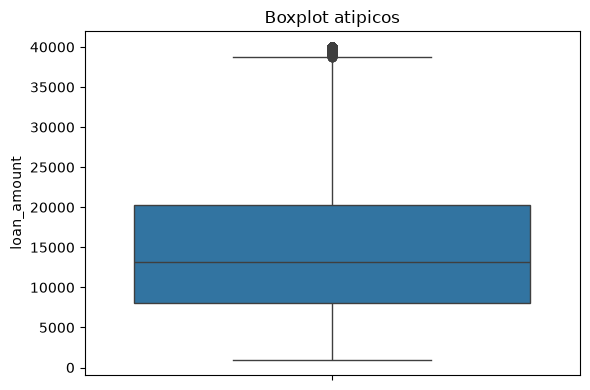

,loan_id,customer_id,loan_status,loan_amount,state,funded_amount,term,int_rate,installment,grade,issue_d,issue_date,issue_year,pymnt_plan,type,purpose,description,notes
19215,268744,b';\xe7\xa3\x85\x10\xbb-\xc8W\xc3\xf5\xa5ha\xf...,Current,40000.0,MO,40000.0,60 months,0.1199,889.58002,C,Apr-16,April 2016,2016.0,False,INDIVIDUAL,credit_card,Credit card refinancing,desc
19424,264619,b'\xfe\\\xac\x89Ki\x81\x9bfa\x87\xe25\x92Xc\x9...,Current,40000.0,FL,40000.0,36 months,0.0532,1204.60000,A,Apr-16,April 2016,2016.0,False,INDIVIDUAL,debt_consolidation,Debt consolidation,desc
19425,267187,b'\xa7\xf6U\xd4\'\xf4\n\r\x02$\x83\x88X|\x0f-\...,Fully Paid,40000.0,TN,40000.0,36 months,0.1825,1451.12000,D,Apr-16,April 2016,2016.0,False,INDIVIDUAL,other,Other,desc
19569,264575,b'gj\x9b\x98\xaf|\xdf\x8a\xf7\x03\xd5\x8a\x13z...,Current,40000.0,NJ,40000.0,36 months,0.0532,1204.60000,A,Apr-16,April 2016,2016.0,False,INDIVIDUAL,small_business,Business,desc
19634,264394,b'\xc7\xe8\x86s\x8f\xba\x82PG\xee\x871\xa6B\xe...,Current,40000.0,NV,40000.0,60 months,0.1075,864.71997,B,Apr-16,April 2016,2016.0,False,INDIVIDUAL,home_improvement,Home improvement,desc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
270294,265718,b'W\\/\x9e\x0c5\x1b\x1eC\x8c\x8aM\xbc+\x1c~\x0...,Current,40000.0,MD,40000.0,36 months,0.0756,1245.36000,A,Sep-19,September 2019,2019.0,False,Individual,debt_consolidation,Debt consolidation,desc
270295,266053,b'\x8d\n\x1aF!\xc1\x9e6`\xe5TQ\x9a\xc3x\x82\x8...,Current,40000.0,TN,40000.0,36 months,0.0819,1256.97000,A,Sep-19,September 2019,2019.0,False,Joint App,debt_consolidation,Debt consolidation,desc
270296,267554,b'\xf1\xa3Y\x83\x81J=\xbe\xf6\xfe9\x15\xb4-\xd...,Current,40000.0,IL,40000.0,60 months,0.0819,814.70001,A,Sep-19,September 2019,2019.0,False,Individual,credit_card,Credit card refinancing,desc
270297,267598,"b""*?\x0c\x05e\xce\x1c\x16\xef\x18R\xf7\x94l\xf...",Current,40000.0,TX,40000.0,60 months,0.0819,814.70001,A,Sep-19,September 2019,2019.0,False,Individual,debt_consolidation,Debt consolidation,desc


In [7]:
detectar_outliers(loan, 'loan_amount')

int_rate: registros atipicos: 4260 - 1.58%


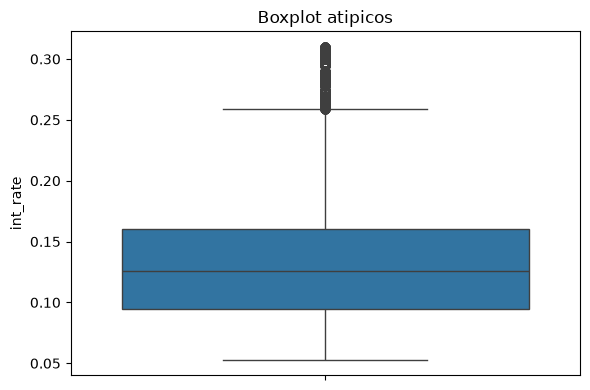

,loan_id,customer_id,loan_status,loan_amount,state,funded_amount,term,int_rate,installment,grade,issue_d,issue_date,issue_year,pymnt_plan,type,purpose,description,notes
219,206879,"b""\xe0\xfd\x83I\x03,L\xcf`\xe7\x89\xbbgQ\xaaq\...",Charged Off,21000.0,OR,21000.0,60 months,0.2589,627.39001,G,Jul-13,July 2013,2013.0,False,INDIVIDUAL,debt_consolidation,debt consolidation,desc
514,229822,b'\x9d\x00\xf9\x11fp\xbac\x1c\x8eb\xbd\xc3\xa6...,Fully Paid,25000.0,CA,25000.0,60 months,0.2589,746.89001,G,Sep-14,September 2014,2014.0,False,INDIVIDUAL,debt_consolidation,Debt consolidation,desc
1547,202166,b'\xce\xe1\xe6\xbc\xb6\xd5\x9b(W\xc5\x1d\xf7^k...,Fully Paid,20000.0,NJ,20000.0,60 months,0.2589,597.51001,G,Jul-13,July 2013,2013.0,False,INDIVIDUAL,debt_consolidation,helful loan,desc
1980,104202,"b'E\xae\xc7\x9b\xb8\xc2h\xc8N\x16,\xfe~Av\xbd?...",Fully Paid,10000.0,NV,10000.0,60 months,0.2599,299.35001,G,Aug-13,August 2013,2013.0,False,INDIVIDUAL,debt_consolidation,Debt Consolidation Loan,desc
2345,169503,b'\xd8\x1b\xc5\xd4S\xa2\xc9\xef\xe4\x1e\x04Uc\...,Charged Off,16000.0,CA,16000.0,60 months,0.2589,478.01001,G,Aug-13,August 2013,2013.0,False,INDIVIDUAL,other,Investment,desc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269799,37130,b'\x01\x01\xc0\x14i\xdb\x1c4:\xdcr\xc3y\xa3Pn\...,Fully Paid,5500.0,WI,5500.0,36 months,0.2880,229.89000,D,Sep-19,September 2019,2019.0,False,Individual,debt_consolidation,Debt consolidation,desc
270097,247047,"b""|\xc2'\xe6\xf3\xa3m?\xb7\xef\xa0\x0f\xf6\xa3...",Current,30000.0,NM,30000.0,60 months,0.2880,948.60999,D,Sep-19,September 2019,2019.0,False,Individual,debt_consolidation,Debt consolidation,desc
270181,225968,b'(s(\xe5\x9d_@+\r\x96\xf8>B\xc5x#\xc6\xd6U\x8...,Fully Paid,25000.0,OH,25000.0,36 months,0.2880,1044.93010,D,Sep-19,September 2019,2019.0,False,Individual,debt_consolidation,Debt consolidation,desc
270263,161740,b'\x18\xf4\x1d\x92\xdeVB\x1b\x14\x9dj#/\xdc#\x...,Late (31-120 days),15950.0,NJ,15950.0,60 months,0.2880,504.35001,D,Sep-19,September 2019,2019.0,False,Individual,debt_consolidation,Debt consolidation,desc


In [8]:
detectar_outliers(loan, 'int_rate')

installment: registros atipicos: 7943 - 2.94%


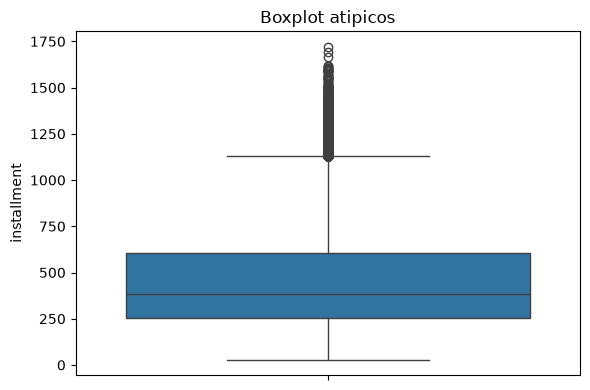

,loan_id,customer_id,loan_status,loan_amount,state,funded_amount,term,int_rate,installment,grade,issue_d,issue_date,issue_year,pymnt_plan,type,purpose,description,notes
260,252934,b'\x1dbo\xb6\r\xc6[\x9f\xd6\x02\xba\x83\x92}\x...,Fully Paid,35000.0,NY,35000.0,36 months,0.1114,1148.1801,B,Oct-12,October 2012,2012.0,False,INDIVIDUAL,debt_consolidation,debt consolidation loan,desc
261,256795,b'H(]\x1a5\xe0$\xf8\xe7QK\x84+\xd0\xfa\xa4m\xe...,Fully Paid,35000.0,CA,35000.0,36 months,0.1580,1227.0500,C,Jan-13,January 2013,2013.0,False,INDIVIDUAL,debt_consolidation,PAY BILLS,desc
262,256960,b'\xa6x\xd4j\xd23Z\x18\x8d_F\x96\xdfX\xa4u\xe8...,Fully Paid,35000.0,TX,35000.0,36 months,0.1629,1235.5200,C,Apr-13,April 2013,2013.0,False,INDIVIDUAL,credit_card,36 month Consolidation Loan,desc
263,257025,b'\xa0\xbe1\xc7*D\x99\x99S\x14|aN\xcf.\xefD;\x...,Fully Paid,35000.0,VA,35000.0,36 months,0.1649,1238.9800,D,Dec-14,December 2014,2014.0,False,INDIVIDUAL,debt_consolidation,Debt consolidation,desc
264,257617,b'\xcb\x98\x17\xe2\x03Q\x07\xc3\xa1?\\\x8bM\x0...,Fully Paid,35000.0,CA,35000.0,36 months,0.1972,1295.7400,D,Sep-12,September 2012,2012.0,False,INDIVIDUAL,wedding,Wedding Loan,desc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
270202,266699,"b""y\x8f\xb8x\xef_D\xab\xed\x13\x0b\xa5qV\xb9\x...",Current,40000.0,CA,40000.0,36 months,0.1102,1309.9301,B,Sep-19,September 2019,2019.0,False,Joint App,debt_consolidation,Debt consolidation,desc
270292,262590,b'\x8b<\xd7Z\xce\xb5t+\xc9\xec\xcb\xbfyx\x1d\t...,Current,36000.0,TX,36000.0,36 months,0.0819,1131.2700,A,Sep-19,September 2019,2019.0,False,Individual,debt_consolidation,Debt consolidation,desc
270293,263438,b'\xbe+u\xdc\x8b10*\xe6\xee\xb8\x1f\x1f=\x1e\x...,Current,37000.0,CA,37000.0,36 months,0.1102,1211.6899,B,Sep-19,September 2019,2019.0,False,Individual,credit_card,Credit card refinancing,desc
270294,265718,b'W\\/\x9e\x0c5\x1b\x1eC\x8c\x8aM\xbc+\x1c~\x0...,Current,40000.0,MD,40000.0,36 months,0.0756,1245.3600,A,Sep-19,September 2019,2019.0,False,Individual,debt_consolidation,Debt consolidation,desc


In [9]:
detectar_outliers(loan, 'installment')

💡 Decision on outliers: the IQR method flags 6,208 loans in `loan_amount` (2.3%), 4,260 in `int_rate` (1.58%) and 7,943 in `installment` (2.94%). None of them are errors. The amount outliers are loans at or near the 40,000 maximum the product allows. The rate outliers are the riskiest grades: rates above roughly 26% are how F and G are priced. The installment outliers follow from those large amounts. These are legitimate loans and an important part of the risk analysis, so I keep them, as I did with the wholesale orders in RappiPlus.

---

### 1.3 Data Review: `customer`

In [10]:
explorar_datos(customer, 'customer')

--- Dataset: customer ---
270299 filas, 11 columnas
Filas duplicadas: 0 (0.0%)

Estadísticas de columnas numéricas:
         annual_inc  annual_inc_joint    avg_cur_bal   Tot_cur_bal
count  2.702990e+05      1.879400e+04  270299.000000  2.702990e+05
mean   7.961800e+04      1.306721e+05   13668.796092  1.446931e+05
std    8.112625e+04      9.295802e+04   16753.975392  1.639825e+05
min    3.400000e+01      1.540000e+04       0.000000  0.000000e+00
25%    4.735250e+04      8.660000e+04    3107.000000  2.948200e+04
50%    6.600000e+04      1.150000e+05    7376.000000  8.047800e+04
75%    9.500000e+04      1.540750e+05   18921.500000  2.165500e+05
max    9.550000e+06      7.874821e+06  623229.000000  9.971659e+06


,tipo,nulos,% nulos,valores_distintos,ejemplo
customer_id,str,0,0.00,270299,b'\xa0\xe6\x1a\xc8H\xbd/(T]\x13[\xf5\x0fK\xd9\...
emp_title,str,23662,8.75,88932,Care Giver
emp_length,str,18745,6.93,11,1 year
home_ownership,str,0,0.00,6,RENT
annual_inc,float64,0,0.00,19266,25000.0
annual_inc_joint,float64,251505,93.05,3866,118000.0
verification_status,str,0,0.00,3,Verified
zip_code,str,0,0.00,887,010xx
addr_state,str,0,0.00,51,MA
avg_cur_bal,float64,0,0.00,50933,6864.0


`customer` has 270,299 rows, 11 columns and no duplicates. `customer_id` is unique, which confirms the one-to-one relationship with `loan`. The issues sit in four places:

- **Nulls:** `annual_inc_joint` (93.05%), `emp_title` (8.75%) and `emp_length` (6.93%).
- **Implausible income at both ends:** `annual_inc` goes from 34 (impossible for someone who received at least 1,000) to 9.55 million. The median is 66,000.
- **Existing debt above income:** the median of `Tot_cur_bal` (80,478) is higher than the median income, which suggests it includes mortgages.
- **Free text:** `emp_title` has 88,932 distinct values, far too many to use as a category.

In [11]:
customer_cat = ['emp_title','emp_length','home_ownership','verification_status']

revisar_categoricas(customer, customer_cat)

emp_title: 
                              total     %
emp_title                               
NaN                          23662  8.75
Teacher                       4649  1.72
Manager                       4156  1.54
Owner                         2288  0.85
Registered Nurse              1988  0.74
...                            ...   ...
Certified Nursing Aide           1  0.00
Sr. Puser                        1  0.00
Sr. Purser                       1  0.00
Assistant attorney general       1  0.00
Surface Equipment Operator       1  0.00

[88933 rows x 2 columns] 

emp_length: 
             total      %
emp_length              
10+ years   88549  32.76
< 1 year    24652   9.12
2 years     24036   8.89
3 years     21452   7.94
NaN         18745   6.93
1 year      17722   6.56
5 years     16665   6.17
4 years     16207   6.00
6 years     11870   4.39
7 years     10823   4.00
8 years     10533   3.90
9 years      9045   3.35 

home_ownership: 
                  total      %
home_ownersh

💡 Categories in `customer`: `emp_title` is indeed free text written in many ways (`Sr. Purser` and `Sr. Puser`). `home_ownership` has three main categories (MORTGAGE 49.34%, RENT 39.09%, OWN 11.44%) and three residual ones (ANY, OTHER, NONE: 355 rows, 0.13%), which I'll group as `OTHER`. `verification_status` has three levels: Source Verified (38.98%), Not Verified (36.20%) and Verified (24.82%).

💡 Decision on nulls in `customer`: before treating a null, I ask why it's missing and whether I use the column at all.

- `emp_length` (6.93%): the customer didn't report it. Filling it with the mode would invent information, and dropping the rows would lose loans with a known outcome. So T2 keeps the nulls as their own group (`Sin dato`), and Step 5 measures whether that group behaves differently.
- `emp_title` (8.75%): I don't use it, so its nulls don't matter.
- `annual_inc_joint` (93.05%): this may be a **structural** null, one that only exists when there's a co-borrower. I check it below instead of assuming it.

`verification_status` has three levels. T2 merges `Source Verified` into `verified`, so Step 5 can compare verification as a yes/no.

💡 Structural nulls: `annual_inc_joint` should only exist for joint applications. I cross each loan's type with whether it has joint income.

In [12]:
prestamo_cliente = loan[['customer_id', 'type', 'state']].merge(customer, on='customer_id', how='left') # cada préstamo con su cliente
pd.crosstab(prestamo_cliente['type'], prestamo_cliente['annual_inc_joint'].isnull()) # True = sin ingreso conjunto

annual_inc_joint,False,True
type,,
DIRECT_PAY,0,303
INDIVIDUAL,0,81709
Individual,0,169493
JOINT,863,0
Joint App,17931,0


The crosstab confirms it. All 18,794 joint loans have joint income, and none of the 251,505 individual or direct-pay loans do. The nulls are structural, so I leave them as they are. They do change one calculation: in a joint loan the installment is paid with two incomes, so T3 uses an **effective income** (joint income for joint applications, individual income for the rest) to measure the payment burden.

---

### 1.4 Data Review: `state_region`

In [13]:
explorar_datos(state_region, 'region')

--- Dataset: region ---
52 filas, 3 columnas
Filas duplicadas: 0 (0.0%)

Estadísticas de columnas numéricas:
       state       subregion region
count     52              52     52
unique    52              10      5
top       AK  South Atlantic  South
freq       1               9     17


,tipo,nulos,% nulos,valores_distintos,ejemplo
state,str,0,0.0,52,AK
subregion,str,0,0.0,10,Pacific
region,str,0,0.0,5,West


`state_region` is a small reference table (52 rows) with no nulls or duplicates. But `loan` has 51 states. The extra row is the original header (`state`, `subregion`, `region`), stored as data in the source table. The SQL review in Step 2 confirms it, and T1 removes that row.

💡 **Cleaning decisions.** Each issue, its evidence, the decision and the SQL query that applies it. Every decision rests on something this exploration showed, not on an assumption:

| Issue | Evidence | Decision | Applied in |
|---|---|---|---|
| `type` written in 4 ways | Individual 62.71%, INDIVIDUAL 30.23%, Joint App 6.63%, JOINT 0.32% | Merge into individual, joint, direct_pay | T3 |
| Dates as text in three columns | `Jun-13`, `June 2013`, `2013.0` | Keep one date, `issue_date`, parsed with its exact format; V1 checks that no date is left null | T3 |
| `notes` and `description` without value | `notes` has one value; `description` repeats `purpose` | Not selected | T3 |
| Nulls in `emp_length` | 6.93%, not reported | Own group `Sin dato` | T2 |
| Nulls in `annual_inc_joint` | 93.05%, structural (crosstab) | Kept as null; effective income for joint loans | T2, T3 |
| Implausible income | Minimum 34 per year | Income below 1,000 set to null | T2 |
| Residual `home_ownership` categories | ANY, OTHER, NONE: 0.13% | Grouped as `OTHER` | T2 |
| `Source Verified` | 38.98% | Merged into `verified` | T2 |
| `emp_title` and `zip_code` | Free text / repeats the state | Not selected | T2 |
| Header stored as a row | 52 rows vs 51 states | Row removed | T1 |
| Installments that don't cover the principal | 7 loans (D1) | Excluded | T3 |

---

## 🔹 Step 2: Data Quality Checks in BigQuery (SQL)

**🎯 My objective:** Run the quality checks on the raw tables in BigQuery, where the transformation will happen, and catch the issues that are easier to see in SQL.

⚙️ **SQL cells**: from here on, every query runs in a `%%bigquery` cell, pure SQL with no Python around it. A cell without a name just shows its result. A cell with a name (`%%bigquery calidad`) saves the result as a DataFrame, so the next cell can display or plot it.

In [14]:
%load_ext bigquery_magics
import bigquery_magics
bigquery_magics.context.project = 'fintech-510922'

💡 General quality in one query. Two CTEs prepare the data (`cli`, one row per customer; `lj`, each loan with its customer), and the final `SELECT` returns a single row with nine checks. `COUNT(*) OVER (PARTITION BY ...)` flags repeated keys without collapsing rows, and `COUNTIF` counts the rows that fail each check.

In [15]:
%%bigquery calidad
WITH cli AS (
  SELECT customer_id, ANY_VALUE(addr_state) AS addr_state, COUNT(*) AS filas
  FROM `fintech-510922.fintech_raw.customer`
  GROUP BY customer_id
),
lj AS (
  SELECT
    l.*,
    c.customer_id IS NOT NULL AS tiene_cliente,
    c.addr_state,
    COUNT(*) OVER (PARTITION BY l.loan_id) AS rep_loan,
    COUNT(*) OVER (PARTITION BY l.customer_id) AS prestamos_del_cliente,
    SAFE_CAST(REGEXP_EXTRACT(l.term, r'\d+') AS INT64) AS meses
  FROM `fintech-510922.fintech_raw.loan` l
  LEFT JOIN cli c USING (customer_id)
)
SELECT
  DISTINCT COUNT(*) AS prestamos,
  COUNTIF(rep_loan > 1) AS filas_loan_duplicadas,
  COUNTIF(NOT tiene_cliente)AS prestamos_sin_cliente,
  COUNT(DISTINCT IF(prestamos_del_cliente > 1, customer_id, NULL)) AS clientes_con_varios_prestamos,
  (SELECT COUNTIF(filas > 1) FROM cli) AS clientes_duplicados,
  COUNTIF(funded_amount > loan_amount) AS fondeado_mayor_que_solicitado,
  COUNTIF(funded_amount < loan_amount) AS fondeado_menor_que_solicitado,
  COUNTIF(installment * meses < funded_amount) AS cuotas_no_cubren_capital,
  COUNTIF(UPPER(TRIM(state)) != UPPER(TRIM(addr_state))) AS estado_distinto_entre_tablas
FROM lj;

Query is running:   0%|          |

Downloading:   0%|          |

In [16]:
calidad

,prestamos,filas_loan_duplicadas,prestamos_sin_cliente,clientes_con_varios_prestamos,clientes_duplicados,fondeado_mayor_que_solicitado,fondeado_menor_que_solicitado,cuotas_no_cubren_capital,estado_distinto_entre_tablas
0,270299,0,0,0,0,0,0,7,0


Every check returns 0 except one: **7 loans whose installments don't cover the amount lent** (`installment × months < funded_amount`). I pull those rows to look at them.

In [17]:
%%bigquery revisar_cuotas
SELECT
  loan_id, term, loan_status, pymnt_plan, installment, funded_amount,
  installment * SAFE_CAST(REGEXP_EXTRACT(term, r'\d+') AS INT64) AS total_cuotas,
  funded_amount - installment * SAFE_CAST(REGEXP_EXTRACT(term, r'\d+') AS INT64) AS diferencia,
FROM `fintech-510922.fintech_raw.loan`
WHERE installment * SAFE_CAST(REGEXP_EXTRACT(term, r'\d+') AS INT64) < funded_amount;

Query is running:   0%|          |

Downloading:   0%|          |

In [18]:
revisar_cuotas

,loan_id,term,loan_status,pymnt_plan,installment,funded_amount,total_cuotas,diferencia
0,22950,36 months,Current,False,97.779999,4750.0,3520.079964,1229.920036
1,107852,36 months,Fully Paid,False,172.280000,10725.0,6202.080000,4522.920000
2,145685,36 months,Fully Paid,False,371.200010,15000.0,13363.200360,1636.799640
3,36236,36 months,Current,False,123.870000,5500.0,4459.320000,1040.680000
4,132482,36 months,Fully Paid,False,168.899990,13000.0,6080.399640,6919.600360
5,8044,36 months,Fully Paid,False,66.860001,2600.0,2406.960036,193.039964
6,51153,36 months,Current,False,188.710010,6800.0,6793.560360,6.439640


💡 Inconsistent installments: all 7 are 36-month loans (4 Fully Paid, 3 Current). In the worst case (loan 132482), 36 installments of 168.90 add up to 6,080 for a 13,000 loan. The lowest rate in the portfolio is 5.31%, so installments can never add up to less than the principal. Something in these records is wrong: the installment, the amount or the term. They're 7 out of 270,299 and barely move the KPIs, but their contractual interest comes out negative and would distort the margin. Decision: T3 excludes them (`installment × term_months >= funded_amount`).

💡 Nulls in every column without naming them: each row becomes JSON text (`TO_JSON_STRING`), a regular expression pulls out the keys whose value is `null` or `""` (`REGEXP_EXTRACT_ALL`), and `UNNEST` turns them into rows that can be counted.

In [19]:
%%bigquery nulos
SELECT tabla, columna, COUNT(*) AS nulos_o_vacios
FROM (
  SELECT 'loan' AS tabla, TO_JSON_STRING(t) AS fila FROM `fintech-510922.fintech_raw.loan` t
  UNION ALL
  SELECT 'customer', TO_JSON_STRING(t) FROM `fintech-510922.fintech_raw.customer` t
),
UNNEST(REGEXP_EXTRACT_ALL(fila, r'"(\w+)":(?:null|"")')) AS columna
GROUP BY tabla, columna
ORDER BY tabla, nulos_o_vacios DESC;

Query is running:   0%|          |

Downloading:   0%|          |

In [20]:
nulos

,tabla,columna,nulos_o_vacios
0,customer,annual_inc_joint,251505
1,customer,emp_title,23662
2,customer,emp_length,18745
3,loan,description,2343


The SQL count matches the Python diagnostic exactly. There are nulls only in `annual_inc_joint` (251,505), `emp_title` (23,662), `emp_length` (18,745) and `description` (2,343). Columns that don't show up have no nulls or empty texts.

💡 Categories of every text column at once: `UNPIVOT` turns columns into rows (one row per cell), so a single `GROUP BY` counts the categories of ten columns. `SUM(COUNT(*)) OVER (PARTITION BY columna)` gives each column's total for the percentages, and `RANK()` orders the categories by frequency.

In [21]:
%%bigquery categorias
WITH cats AS (
  SELECT columna, valor
  FROM (
    SELECT loan_status, term, grade, type, purpose, state,
           CAST(pymnt_plan AS STRING) AS pymnt_plan
    FROM `fintech-510922.fintech_raw.loan`
  )
  UNPIVOT INCLUDE NULLS (valor FOR columna IN (loan_status, term, grade, type, purpose, state, pymnt_plan))
  UNION ALL
  SELECT columna, valor
  FROM (
    SELECT home_ownership, verification_status, emp_length
    FROM `fintech-510922.fintech_raw.customer`
  )
  UNPIVOT INCLUDE NULLS (valor FOR columna IN (home_ownership, verification_status, emp_length))
)
SELECT
  columna,
  valor,
  COUNT(*) AS conteo,
  ROUND(COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY columna) * 100, 2) AS pct,
  RANK() OVER (PARTITION BY columna ORDER BY COUNT(*) DESC) AS ranking
FROM cats
GROUP BY columna, valor
ORDER BY columna, ranking;

Query is running:   0%|          |

Downloading:   0%|          |

In [22]:
categorias

,columna,valor,conteo,pct,ranking
0,emp_length,10+ years,88549,32.76,1
1,emp_length,< 1 year,24652,9.12,2
2,emp_length,2 years,24036,8.89,3
3,emp_length,3 years,21452,7.94,4
4,emp_length,NaN,18745,6.93,5
...,...,...,...,...,...
103,type,JOINT,863,0.32,4
104,type,DIRECT_PAY,303,0.11,5
105,verification_status,Source Verified,105373,38.98,1
106,verification_status,Not Verified,97851,36.20,2


The 108 categories confirm what Python showed: `type` split by formatting, three verification levels and 18,745 null `emp_length` values.

💡 Numeric ranges: the same `UNPIVOT` with the numeric columns, plus percentiles 1, 50 and 99 (`APPROX_QUANTILES`). The percentiles tell me whether an extreme value is isolated or typical.

In [23]:
%%bigquery rangos
WITH nums AS (
  SELECT variable, valor
  FROM (
    SELECT loan_amount, funded_amount, int_rate, installment, issue_year
    FROM `fintech-510922.fintech_raw.loan`
  )
  UNPIVOT (valor FOR variable IN (loan_amount, funded_amount, int_rate, installment, issue_year))
  UNION ALL
  SELECT variable, valor
  FROM (
    SELECT annual_inc, annual_inc_joint, avg_cur_bal, Tot_cur_bal
    FROM `fintech-510922.fintech_raw.customer`
  )
  UNPIVOT (valor FOR variable IN (annual_inc, annual_inc_joint, avg_cur_bal, Tot_cur_bal))
)
SELECT
  variable,
  COUNT(*) AS conteo,
  MIN(valor) AS minimo,
  APPROX_QUANTILES(valor, 100)[OFFSET(1)] AS p01,
  APPROX_QUANTILES(valor, 100)[OFFSET(50)] AS mediana,
  APPROX_QUANTILES(valor, 100)[OFFSET(99)] AS p99,
  MAX(valor) AS maximo,
  COUNTIF(valor <= 0) AS ceros_o_negativos
FROM nums
GROUP BY variable
ORDER BY variable;

Query is running:   0%|          |

Downloading:   0%|          |

In [24]:
rangos

,variable,conteo,minimo,p01,mediana,p99,maximo,ceros_o_negativos
0,Tot_cur_bal,270299,0.0000,2705.000000,80455.00000,693953.0000,9.971659e+06,10
1,annual_inc,270299,34.0000,16842.000000,66000.00000,278000.0000,9.550000e+06,0
2,annual_inc_joint,18794,15400.0000,38788.000000,115000.00000,392000.0000,7.874821e+06,0
3,avg_cur_bal,270299,0.0000,432.000000,7378.00000,76296.0000,6.232290e+05,14
4,funded_amount,270299,1000.0000,1500.000000,13200.00000,40000.0000,4.000000e+04,0
5,installment,270299,29.5200,53.139999,383.95999,1246.9800,1.719830e+03,0
6,int_rate,270299,0.0531,0.053200,0.12610,0.2727,3.099000e-01,0
7,issue_year,270299,2012.0000,2013.000000,2017.00000,2019.0000,2.019000e+03,0
8,loan_amount,270299,1000.0000,1500.000000,13200.00000,40000.0000,4.000000e+04,0


`annual_inc` has implausible values at both ends: a minimum of 34 and a maximum of 9.55 million, while 98% of customers earn between 16,842 and 278,000 (p01 and p99). T2 will set income below 1,000 to unknown. High incomes don't affect the income bands. The median existing debt (80,455) is above the median income (66,000), which fits with `Tot_cur_bal` including mortgages. Only 10 customers have no current debt, and `int_rate` confirms that rates are stored as decimals.

💡 Values of `state_region`: I list every value of its three columns to look at the 52nd row.

In [25]:
%%bigquery state
WITH region AS (
  SELECT variable, valor
  FROM (
    SELECT region, subregion, state
    FROM `fintech-510922.fintech_raw.state_region`
  )
  UNPIVOT (valor FOR variable IN (region, subregion, state))
)
SELECT
  variable,
  valor,
  COUNT(valor) AS conteo,
  ANY_VALUE(valor) AS ejemplo
FROM region
GROUP BY variable, valor
ORDER BY variable;

Query is running:   0%|          |

Downloading:   0%|          |

In [26]:
state

,variable,valor,conteo,ejemplo
0,region,West,13,West
1,region,South,17,South
2,region,region,1,region
3,region,Midwest,12,Midwest
4,region,Northeast,9,Northeast
...,...,...,...,...
62,subregion,subregion,1,subregion
63,subregion,East North Central,5,East North Central
64,subregion,West North Central,7,West North Central
65,subregion,New England,6,New England


Confirmed. `region` contains the value `region`, `subregion` contains `subregion` and `state` contains `state`. The table's own header is stored as a data row, and it would show up as a fifth region in every regional analysis. T1 removes it.

💡 Date formats (D5): T3 converts the text date with `PARSE_DATE`, which only works if every row uses the same format. Rather than assume that, I replace every digit with `9` and every letter with `A`. Dates written the same way turn into the same pattern and can be counted together. **What I expect:** one pattern per column with the same structure (month, separator, year). That tells me which format `PARSE_DATE` needs.

In [27]:
%%bigquery fechas
SELECT
  columna,
  REGEXP_REPLACE(REGEXP_REPLACE(valor, r'\d', '9'), r'[A-Za-z]', 'A') AS patron,   -- dígitos → 9, letras → A
  COUNT(*)          AS n,
  ANY_VALUE(valor)  AS ejemplo
FROM `fintech-510922.fintech_raw.loan`
UNPIVOT (valor FOR columna IN (issue_d, issue_date))
GROUP BY columna, patron
ORDER BY columna, n DESC;

Query is running:   0%|          |

Downloading:   0%|          |

In [28]:
fechas

,columna,patron,n,ejemplo
0,issue_d,AAA-99,270299,Apr-18
1,issue_date,AAAAAAAA 9999,65815,December 2015
2,issue_date,AAAAAAA 9999,47154,January 2016
3,issue_date,AAAA 9999,46338,June 2018
4,issue_date,AAAAA 9999,43902,April 2018
5,issue_date,AAAAAA 9999,24026,August 2016
6,issue_date,AAA 9999,21970,May 2017
7,issue_date,AAAAAAAAA 9999,21094,September 2015


`issue_d` has a single pattern (`AAA-99`, as in `Jun-13`). `issue_date` only varies in the length of the month name (`AAAA 9999` for `June 2013`, `AAAAAAAAA 9999` for `September 2013`), but its structure never changes: full month, a space and a four-digit year. With one format per column, T3 can parse each one with its exact format (`'%b-%y'` and `'%B %Y'`), and V1 checks afterwards that no date was left null.

---

## 🔹 Step 3: Transform the Data into a Clean Model (SQL)

**🎯 My objective:** Turn the cleaning decisions into clean tables inside `fintech_clean`, organized as a star model.

- `dim_region` (T1): one row per state, with its subregion and region
- `dim_customer` (T2): one row per customer, with the customer cleaning rules
- `fact_loan` (T3): one row per loan, with the loan cleaning rules and the indicators the KPIs use
- `view_loan` (T4): a view that joins the three tables; every KPI and the Looker dashboard read from it

Dimension tables (*dim*) describe things. The fact table (*fact*) records what happens. KPIs are calculated on the fact table and sliced by the dimensions.

💡 T1: `SELECT DISTINCT` guarantees one row per state, `UPPER(TRIM(state))` makes the codes match the ones in `loan`, and `LOWER(TRIM(state)) != 'state'` drops the header row.

In [29]:
%%bigquery
CREATE OR REPLACE TABLE `fintech-510922.fintech_clean.dim_region` AS
SELECT DISTINCT
  UPPER(TRIM(state)) AS state,      
  TRIM(subregion)    AS subregion,  
  TRIM(region)       AS region     
FROM `fintech-510922.fintech_raw.state_region`
WHERE state IS NOT NULL
  AND LOWER(TRIM(state)) != 'state';  -- quita la fila del encabezado que viene como dato


Query is running:   0%|          |

""


💡 T2 applies every customer decision:

- `FARM_FINGERPRINT` turns the long binary `customer_id` into a numeric key. T3 uses the same function, so the keys match.
- `COALESCE(..., 'Sin dato')` keeps missing employment length as its own group.
- Residual housing categories go to `OTHER`, income below 1,000 becomes null and `Source Verified` is merged into `verified`.
- `income_band` creates the income ranges.
- `QUALIFY ROW_NUMBER() ... = 1` guarantees one row per customer.

In [30]:
%%bigquery
CREATE OR REPLACE TABLE `fintech-510922.fintech_clean.dim_customer` AS
SELECT
  FARM_FINGERPRINT(customer_id) AS customer_key,
  CASE
    WHEN TRIM(emp_length) LIKE '<%' THEN 0
    ELSE SAFE_CAST(REGEXP_EXTRACT(emp_length, r'\d+') AS INT64)
  END AS emp_length_years,
  COALESCE(TRIM(emp_length), 'Sin dato') AS emp_length,      -- nulos como grupo aparte
  IF(UPPER(TRIM(home_ownership)) IN ('MORTGAGE', 'RENT', 'OWN'),
     UPPER(TRIM(home_ownership)), 'OTHER') AS home_ownership,
  IF(annual_inc < 1000, NULL, annual_inc) AS annual_inc,      -- ingreso anual < 1000 no es creíble
  annual_inc_joint,
  IF(LOWER(TRIM(verification_status))='source verified','verified', LOWER(TRIM(verification_status))) AS verification_status,
  CASE
    WHEN annual_inc IS NULL OR annual_inc < 1000 THEN 'Sin dato'
    WHEN annual_inc < 40000  THEN '1. <40k'
    WHEN annual_inc < 70000  THEN '2. 40k-70k'
    WHEN annual_inc < 100000 THEN '3. 70k-100k'
    WHEN annual_inc < 150000 THEN '4. 100k-150k'
    ELSE '5. 150k+'
  END AS income_band,
  UPPER(TRIM(addr_state)) AS addr_state,
  avg_cur_bal,
  Tot_cur_bal AS tot_cur_bal
FROM `fintech-510922.fintech_raw.customer`
WHERE customer_id IS NOT NULL
QUALIFY ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY annual_inc DESC) = 1;  

Query is running:   0%|          |

""


💡 T3 is a chain of CTEs, and each one uses columns that the previous one created.

- `limpio`: cleans column by column. It groups the seven statuses into five business groups (`status_group`), extracts the term in months, converts rates to percentages, parses the text date with its exact format and merges the loan types. It also drops the 7 loans whose installments don't cover the amount lent.
- `enriquecido`: joins each loan with its clean customer and calculates the **effective income** (joint income for joint loans).
- `ratios`: three payment-capacity indicators. Installment over income (`payment_to_income`), amount over income, and existing debt over income (`debt_to_income`).
- Final `SELECT`: the 0/1 indicators that turn counting into summing (`is_resolved`, `is_default`, `is_delinquent`, `is_active`), the contractual interest, the maximum loss and the bands `pti_band` and `debt_band`. The maximum loss (`loss_upper_bound`) is the full amount of each defaulted loan. It's an upper bound, because there's no payment data.

In [31]:
%%bigquery
CREATE OR REPLACE TABLE `fintech-510922.fintech_clean.fact_loan` AS
WITH limpio AS (
  SELECT
    l.loan_id,
    FARM_FINGERPRINT(l.customer_id) AS customer_key,
    TRIM(l.loan_status) AS loan_status,
    CASE
      WHEN TRIM(l.loan_status) = 'Fully Paid' THEN 'Pagado'
      WHEN TRIM(l.loan_status) = 'Charged Off' OR TRIM(l.loan_status) = 'Default' THEN 'Incumplido'
      WHEN TRIM(l.loan_status) LIKE 'Late%' THEN 'En mora'
      WHEN TRIM(l.loan_status)= 'In Grace Period' THEN 'En gracia'
      WHEN TRIM(l.loan_status) = 'Current' THEN 'Al día'
      ELSE 'Otro'
    END AS status_group,
    l.loan_amount,
    l.funded_amount,
    SAFE_CAST(REGEXP_EXTRACT(l.term, r'\d+') AS INT64) AS term_months,
    IF(l.int_rate < 1, l.int_rate * 100, l.int_rate) AS int_rate_pct,
    l.installment,
    UPPER(TRIM(l.grade)) AS grade,
    UPPER(TRIM(l.state)) AS state,
    COALESCE(SAFE.PARSE_DATE('%B %Y', l.issue_date),
             SAFE.PARSE_DATE('%b-%y', l.issue_d)) AS issue_date, 
    TRIM(l.purpose)                                         AS purpose,
    CASE LOWER(TRIM(l.type))
        WHEN 'joint app' THEN 'joint'                              
        ELSE LOWER(TRIM(l.type))
    END                                                     AS loan_type,
    l.pymnt_plan
  FROM `fintech-510922.fintech_raw.loan` l
  WHERE l.loan_id IS NOT NULL AND l.funded_amount > 0
    -- se excluyen préstamos cuyas cuotas no alcanzan a pagar lo prestado (registros inconsistentes)
    AND l.installment * SAFE_CAST(REGEXP_EXTRACT(l.term, r'\d+') AS INT64) >= l.funded_amount
  QUALIFY ROW_NUMBER() OVER (PARTITION BY l.loan_id ORDER BY l.issue_date DESC) = 1
),
enriquecido AS (
  SELECT
    f.*,
    c.tot_cur_bal,
    -- ingreso efectivo: en solicitudes conjuntas cuenta el ingreso de los dos
    IF(f.loan_type = 'joint', COALESCE(c.annual_inc_joint, c.annual_inc), c.annual_inc) AS ingreso_efectivo
  FROM limpio f
  LEFT JOIN `fintech-510922.fintech_clean.dim_customer` c USING (customer_key)
),
ratios AS (
  SELECT
    * EXCEPT (tot_cur_bal),
    SAFE_DIVIDE(installment * 12, ingreso_efectivo) AS payment_to_income,  -- cuota anual / ingreso
    SAFE_DIVIDE(funded_amount, ingreso_efectivo)    AS loan_to_income,     -- monto / ingreso
    SAFE_DIVIDE(tot_cur_bal, ingreso_efectivo)      AS debt_to_income      -- deuda previa / ingreso
  FROM enriquecido
)
SELECT
  * EXCEPT (payment_to_income, loan_to_income, debt_to_income),
  EXTRACT(YEAR FROM issue_date)                                      AS issue_year,
  CAST(status_group IN ('Pagado', 'Incumplido') AS INT64)            AS is_resolved,
  CAST(status_group = 'Incumplido' AS INT64)                         AS is_default,
  CAST(status_group IN ('En mora', 'En gracia') AS INT64)            AS is_delinquent,
  CAST(status_group IN ('Al día', 'En mora', 'En gracia') AS INT64)  AS is_active,
  installment * term_months - funded_amount                          AS contractual_interest,
  IF(status_group = 'Incumplido', funded_amount, 0)                  AS loss_upper_bound,  -- techo: no hay datos de pagos ni recuperaciones
  payment_to_income,
  loan_to_income,
  CASE
    WHEN payment_to_income IS NULL  THEN 'Sin dato'
    WHEN payment_to_income < 0.05   THEN '1. <5%'
    WHEN payment_to_income < 0.10   THEN '2. 5-10%'
    WHEN payment_to_income < 0.15   THEN '3. 10-15%'
    WHEN payment_to_income < 0.20   THEN '4. 15-20%'
    ELSE '5. 20%+'
  END                                                                AS pti_band,
  debt_to_income,
  CASE
    WHEN debt_to_income IS NULL THEN 'Sin dato'
    WHEN debt_to_income < 0.5   THEN '1. <0.5x'
    WHEN debt_to_income < 1     THEN '2. 0.5-1x'
    WHEN debt_to_income < 2     THEN '3. 1-2x'
    WHEN debt_to_income < 4     THEN '4. 2-4x'
    ELSE '5. 4x+'
  END                                                                AS debt_band
FROM ratios;

Query is running:   0%|          |

""


💡 T4 is a view and not a table, because it only joins tables that are already clean. If I correct and recreate T2, the view picks up the change without being rebuilt. `EXCEPT` avoids duplicating the join columns.

In [32]:
%%bigquery
CREATE OR REPLACE VIEW `fintech-510922.fintech_clean.view_loan` AS
SELECT
  f.*,
  c.* EXCEPT (customer_key),
  r.* EXCEPT (state)
FROM `fintech-510922.fintech_clean.fact_loan` f
LEFT JOIN `fintech-510922.fintech_clean.dim_customer` c USING (customer_key)
LEFT JOIN `fintech-510922.fintech_clean.dim_region` r USING (state);

Query is running:   0%|          |

""


### 3.1 Validation

💡 One query compares the raw table with the clean view and returns a single row of checks: rows and money lost in the cleaning, statuses without a group, null dates and terms, loans without a customer or region, duplicated keys and loan types that weren't merged. Every check should be 0. Since this validation covers everything, I don't need to bring the clean tables back into Python to check them again.

In [33]:
%%bigquery validacion
WITH crudo AS (
  SELECT COUNT(*) AS filas, SUM(funded_amount) AS monto
  FROM `fintech-510922.fintech_raw.loan`
),
limpio AS (
  SELECT
    COUNT(*)                         AS filas,
    SUM(funded_amount)               AS monto,
    COUNTIF(status_group = 'Otro')   AS estados_sin_clasificar,
    COUNTIF(issue_date IS NULL)      AS fechas_nulas,
    COUNTIF(term_months IS NULL)     AS plazos_nulos,
    COUNTIF(region IS NULL)          AS prestamos_sin_region,
    COUNTIF(home_ownership IS NULL)  AS prestamos_sin_cliente,
    COUNTIF(loan_type NOT IN ('individual', 'joint', 'direct_pay')) AS tipos_sin_unificar
  FROM `fintech-510922.fintech_clean.view_loan`
),
llaves AS (
  SELECT
    COUNT(*) - COUNT(DISTINCT customer_key) AS llaves_cliente_duplicadas,
    (SELECT COUNT(*) - COUNT(DISTINCT state)
     FROM `fintech-510922.fintech_clean.dim_region`) AS estados_duplicados
  FROM `fintech-510922.fintech_clean.dim_customer`
)
SELECT
  crudo.filas                AS filas_crudo,
  limpio.filas               AS filas_limpio,
  crudo.monto - limpio.monto AS monto_excluido,
  limpio.* EXCEPT (filas, monto),
  llaves.*
FROM crudo, limpio, llaves;

Query is running:   0%|          |

Downloading:   0%|          |

In [34]:
validacion.T

,0
filas_crudo,270299
filas_limpio,270292
monto_excluido,58375.0
estados_sin_clasificar,0
fechas_nulas,0
plazos_nulos,0
prestamos_sin_region,0
prestamos_sin_cliente,0
tipos_sin_unificar,0
llaves_cliente_duplicadas,0


The transformation passes every check: 270,299 rows in, 270,292 out. The 7 rows and 58,375 excluded are exactly the inconsistent-installment loans that T3 removes on purpose, and all nine controls are 0. The clean model is ready for the KPIs.

---

## 🔹 Step 4: Measure How Much the Portfolio Earns and Loses

### 4.1 Global KPIs (P1)

**🎯 My objective:** Get the portfolio's baseline: volume, default, loss, delinquency and interest.

💡 The default rate is calculated over **resolved** loans (paid or defaulted), because an active loan can still go either way. Delinquency is calculated over **active** loans, the only ones that can be late. The CTE `cte_base` adds everything up once, and the final `SELECT` turns those totals into the figures the findings use: the gross margin and its share of the interest, the average loss per defaulted loan, and what one extra point of default would cost (1% of the resolved loans times that average loss).

In [35]:
%%bigquery kpis
WITH
cte_base AS (
    SELECT
        COUNT(*) AS prestamos,
        SUM(funded_amount) AS monto,
        SUM(is_resolved) AS resueltos,
        SUM(is_default) AS incumplidos,
        SUM(IF(status_group = 'Pagado', contractual_interest, 0)) AS interes,
        SUM(loss_upper_bound) AS perdida,
        SUM(is_delinquent) AS mora,
        SUM(is_active) AS activos
    FROM `fintech-510922.fintech_clean.view_loan`
)
SELECT
    prestamos,
    ROUND(monto, 2) AS monto_originado,
    resueltos AS prestamos_resueltos,
    incumplidos AS prestamos_incumplidos,
    ROUND(SAFE_DIVIDE(incumplidos, resueltos) * 100, 2) AS tasa_incumplimiento_pct,
    ROUND(interes, 2) AS interes_cobrado,
    ROUND(perdida, 2) AS perdida_maxima_estimada,
    ROUND(interes - perdida, 2) AS margen_bruto,
    ROUND(SAFE_DIVIDE(interes - perdida, interes) * 100, 2) AS margen_pct_interes,
    ROUND(SAFE_DIVIDE(perdida, incumplidos), 2) AS perdida_promedio_incumplido,
    ROUND(resueltos * 0.01) AS incumplidos_un_punto_mas, -- un punto más de incumplimiento = 1 % de los resueltos
    ROUND(resueltos * 0.01 * SAFE_DIVIDE(perdida, incumplidos), 2) AS costo_un_punto_mas,
    mora AS prestamos_mora,
    ROUND(SAFE_DIVIDE(mora, activos) * 100, 2) AS tasa_mora_pct
FROM cte_base;

Query is running:   0%|          |

Downloading:   0%|          |

In [36]:
kpis.T

,0
prestamos,270292
monto_originado,4166014025.0
prestamos_resueltos,94220
prestamos_incumplidos,17863
tasa_incumplimiento_pct,18.96
interes_cobrado,297527627.9
perdida_maxima_estimada,279669425.0
margen_bruto,17858202.9
margen_pct_interes,6.0
perdida_promedio_incumplido,15656.35


The portfolio has lent 4,166 million across 270,292 loans. Of the 94,224 resolved loans, 17,863 defaulted: a **default rate of 18.96%**. Paid loans generated 297.5 million in contractual interest, and defaulted loans a maximum loss of 279.7 million. That leaves a gross margin of just **17.8 million, 6% of the interest**, before funding, operating and collection costs. Each defaulted loan costs 15,658 on average, so one extra point of default (about 942 more defaults) would cost around 14.8 million, almost the whole margin. Among active loans, 5,614 are late or in grace period (3.19%).

### 4.2 Does the Interest Rate Pay for the Risk? (P4)

💡 For each grade and term I calculate the share of loans, the average rate, the default rate and the risk-adjusted margin (interest minus loss). `LAG(...) OVER (PARTITION BY grade ORDER BY term_months)` brings the 36-month value into the 60-month row of the same grade, so `dif_tasa_vs_36` and `dif_incumplimiento_vs_36` show how much more the 60-month term charges and defaults. The window `SUM(...) OVER ()` puts the portfolio total in every row, to measure what share of the loans and of the loss each group explains.

In [37]:
%%bigquery margen
WITH
cte_grupos AS (
    SELECT
        grade,
        term_months,
        COUNT(*) AS prestamos,
        AVG(int_rate_pct) AS tasa,
        SAFE_DIVIDE(SUM(is_default), SUM(is_resolved)) AS incumplimiento,
        SUM(IF(status_group = 'Pagado', contractual_interest, 0)) AS interes,
        SUM(loss_upper_bound) AS perdida
    FROM `fintech-510922.fintech_clean.view_loan`
    GROUP BY grade, term_months
)
SELECT
    grade,
    term_months,
    prestamos,
    ROUND(SAFE_DIVIDE(prestamos, SUM(prestamos) OVER ()) * 100, 2) AS pct_prestamos,
    ROUND(tasa, 2) AS tasa_interes_promedio,
    ROUND(tasa - LAG(tasa) OVER (PARTITION BY grade ORDER BY term_months), 2) AS dif_tasa_vs_36, -- 60 meses menos 36 meses, dentro del grado
    ROUND(incumplimiento * 100, 2) AS tasa_incumplimiento_pct,
    ROUND((incumplimiento - LAG(incumplimiento) OVER (PARTITION BY grade ORDER BY term_months)) * 100, 2) AS dif_incumplimiento_vs_36,
    ROUND(interes - perdida, 2) AS margen_ajustado,
    ROUND(SAFE_DIVIDE(perdida, SUM(perdida) OVER ()) * 100, 2) AS pct_perdida_total -- parte de la pérdida total que explica cada grupo
FROM cte_grupos
ORDER BY grade, term_months;

Query is running:   0%|          |

Downloading:   0%|          |

In [38]:
margen

,grade,term_months,prestamos,pct_prestamos,tasa_interes_promedio,dif_tasa_vs_36,tasa_incumplimiento_pct,dif_incumplimiento_vs_36,margen_ajustado,pct_perdida_total
0,A,36,53452,19.78,7.19,NaN,5.72,NaN,11395918.66,4.68
1,A,60,4419,1.63,7.93,0.75,8.96,3.24,908301.42,0.29
2,B,36,60394,22.34,10.78,NaN,11.72,NaN,9945447.62,12.39
3,B,60,18677,6.91,11.08,0.29,16.08,4.36,6559482.90,3.97
4,C,36,47931,17.73,14.34,NaN,18.78,NaN,-1581254.04,16.02
5,C,60,27906,10.32,14.53,0.19,26.75,7.98,5525853.91,13.59
6,D,36,21804,8.07,18.77,NaN,25.44,NaN,-4959753.38,10.60
7,D,60,17069,6.32,18.86,0.09,33.90,8.46,2037546.83,12.50
8,E,36,5177,1.92,22.32,NaN,31.70,NaN,-3019174.20,3.79
9,E,60,8252,3.05,21.85,-0.46,42.25,10.55,-3816595.17,12.47


💡 To see the risk of every grade and term combination at a glance, I pivot the table (grades as rows, terms as columns) and plot it as a heatmap.

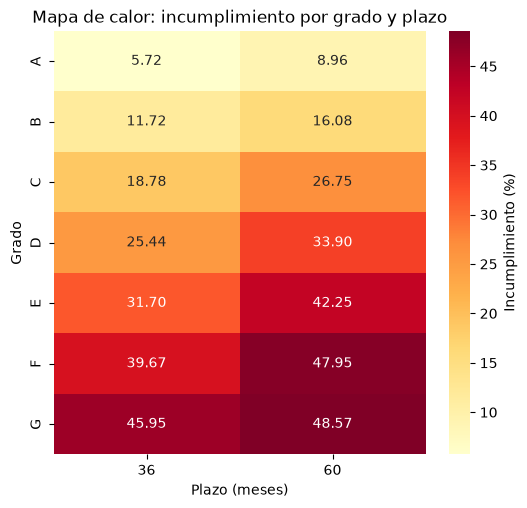

In [39]:
# se crea una matriz con grados como filas y plazos como columnas
matriz_riesgo = margen.pivot(index='grade', columns='term_months', values='tasa_incumplimiento_pct')

# se observa el riesgo por grado y plazo mediante un mapa de calor
plt.figure(figsize=(6, len(matriz_riesgo) * 0.5 + 2))
sns.heatmap(matriz_riesgo, annot=True, fmt='.2f', cmap='YlOrRd', cbar_kws={'label': 'Incumplimiento (%)'})
plt.title('Mapa de calor: incumplimiento por grado y plazo')
plt.xlabel('Plazo (meses)')
plt.ylabel('Grado')
plt.show()

💡 The findings compare groups of grades (A–B, C–D and E–G) and the two terms as a whole. Instead of adding rows by hand, two short queries add them up: `CASE` assigns each grade to its group, and `SUM(...) OVER ()` gives each group's share of the loans and of the loss.

In [40]:
%%bigquery grupos_grado
WITH
cte_grupos AS (
    SELECT
        CASE
            WHEN grade IN ('A', 'B') THEN '1. A-B'
            WHEN grade IN ('C', 'D') THEN '2. C-D'
            ELSE '3. E-G'
        END AS grupo_grado,
        COUNT(*) AS prestamos,
        SUM(IF(status_group = 'Pagado', contractual_interest, 0)) AS interes,
        SUM(loss_upper_bound) AS perdida
    FROM `fintech-510922.fintech_clean.view_loan`
    GROUP BY grupo_grado
)
SELECT
    grupo_grado,
    prestamos,
    ROUND(SAFE_DIVIDE(prestamos, SUM(prestamos) OVER ()) * 100, 2) AS pct_prestamos,
    ROUND(SAFE_DIVIDE(perdida, SUM(perdida) OVER ()) * 100, 2) AS pct_perdida_total,
    ROUND(interes - perdida, 2) AS margen_ajustado
FROM cte_grupos
ORDER BY grupo_grado;

Query is running:   0%|          |

Downloading:   0%|          |

In [41]:
grupos_grado

,grupo_grado,prestamos,pct_prestamos,pct_perdida_total,margen_ajustado
0,1. A-B,136942,50.66,21.33,28809150.60
1,2. C-D,114710,42.44,52.71,1022393.33
2,3. E-G,18640,6.90,25.96,-11973341.03


In [42]:
%%bigquery plazos
SELECT
    term_months,
    COUNT(*) AS prestamos,
    ROUND(SAFE_DIVIDE(COUNT(*), SUM(COUNT(*)) OVER ()) * 100, 2) AS pct_prestamos,
    ROUND(AVG(int_rate_pct), 2) AS tasa_interes_promedio,
    ROUND(SAFE_DIVIDE(SUM(is_default), SUM(is_resolved)) * 100, 2) AS tasa_incumplimiento_pct
FROM `fintech-510922.fintech_clean.view_loan`
GROUP BY term_months
ORDER BY term_months;

Query is running:   0%|          |

Downloading:   0%|          |

In [43]:
plazos

,term_months,prestamos,pct_prestamos,tasa_interes_promedio,tasa_incumplimiento_pct
0,36,189765,70.21,11.98,15.02
1,60,80527,29.79,15.65,31.43


Pricing findings:

- **Grades E, F and G destroy value.** They're 6.9% of loans (18,640) but explain 26.0% of the loss, and all six of their grade-term combinations have a negative margin (−12.0 million together). Default rises much faster than the price: from A to G at 36 months, the rate goes from 7.19% to 29.11%, while default goes from 5.72% to 45.95%.
- **The 60-month term has no price of its own.** It's 29.8% of the portfolio. Within each grade, the 60-month rate is within one point of the 36-month rate (`dif_tasa_vs_36`: +0.7 in A, +0.3 in B, +0.2 in C, +0.1 in D), and in E, F and G it's even lower (−0.5, −0.1 and −0.9). Yet default is higher at 60 months in every grade (`dif_incumplimiento_vs_36`): +3.2 points in A, +4.4 in B, +8.0 in C, +8.5 in D, +10.6 in E, +8.3 in F and +2.6 in G.
- **Grades C and D concentrate half of the loss** (52.7%) with 42.4% of the loans. At 36 months both have negative margins (−1.6 and −5.0 million). At 60 months they show positive ones (+5.5 and +2.0 million), even though they default more. The difference comes from the metric, not from better loans. Contractual interest counts every installment of the term, so a paid 60-month loan adds almost twice the interest of a 36-month one, and if it was prepaid, that interest was never collected. The 60-month margins are an upper bound.
- **Grades A and B carry the profitability** (+28.8 million), with positive margins at both terms.

---

## 🔹 Step 5: Identify Which Segments Concentrate the Risk (P2, P6, P8)

**🎯 My objective:** Find which loan and customer characteristics separate good payers from bad ones, and use statistical tests to prove which of those signals are real, strong enough to use, and not just the grade in disguise.

**The logic, step by step:** each sub-step answers the doubt the previous one leaves open. Only the variables that pass a step move on to the next.

1. **5.1 Describe (K3):** default rate by segment, one variable at a time. It shows where the gaps are and which way they go, but not whether they're real or big enough to matter.
2. **5.2 Filter the categorical variables:** after checking its assumptions, the chi-square test says whether default depends on each variable, and Cramér's V says how strongly. A variable below 0.10 is treated as independent of default and leaves the analysis.
3. **5.3 Confirm the filter with the numeric variables:** the point-biserial correlation measures the same relationship with the original values, so the filter doesn't depend on where I cut the bands.
4. **5.4 Remove repeated information:** the Spearman correlation shows which numeric variables say the same thing, so a rule doesn't use two of them.
5. **5.5 Hold the grade constant (K4, K8):** the two-proportion z-test compares each surviving signal within the same grade. Only what holds here is a signal of its own, and its size decides whether it's worth acting on.
6. **5.6 Explain the verification result (K4):** a chi-square test between verification and grade.

**Which test for which type of variable** (first the type of variable, then the method):

| Variables | Type | Method |
|---|---|---|
| Grade, term, bands, employment length, housing, verification, purpose, region vs default | Categorical vs categorical | Chi-square + Cramér's V |
| Payment-to-income, loan-to-income, debt, income, amount, rate vs default (0/1) | Numeric vs binary | Point-biserial |
| Numeric vs numeric | Numeric vs numeric | Spearman |
| Default of two groups within the same grade | Proportion vs proportion | Two-proportion z-test |

**How I read every result:**

- **p-value** (alpha = 0.05): is there evidence of a relationship or a difference? It says nothing about strength or business importance.
- **Cramér's V and point-biserial** (absolute value): 0.00–0.10 very weak, no relationship · 0.10–0.30 weak · 0.30–0.50 moderate · above 0.50 strong.
- **Spearman:** close to 0, no relationship · ±0.1 to ±0.5 weak · ±0.5 to ±0.8 moderate · above ±0.8 strong, possible collinearity.
- **Direction** comes from the tables and **importance** from the money. A significant difference can still be too small to justify a decision.

---

### 5.1 Default Rate by Segment, One Variable at a Time (K3)

💡 `riesgo_por_segmento` takes a list of columns. For each one it builds the query with an f-string (`{columna}`), runs it in BigQuery with `consultar`, adds each segment's share of the loans (`pct_prestamos`), calculates the **lift** (segment default rate ÷ portfolio average) and plots the result with the average as a red line. It's the only query sent from Python: the column changes on every iteration, and a `%%bigquery` cell can't take a column name as a variable. I expect gaps in payment-to-income, income and housing. This step only describes them.

In [44]:
def riesgo_por_segmento(columnas): # Calcula en BigQuery la tasa de incumplimiento de uno o varios segmentos, la compara con el promedio y la grafica
    
    for columna in columnas:
        query = f'''
        SELECT
            {columna} AS segmento,
            COUNT(*) AS prestamos,
            ROUND(SAFE_DIVIDE(COUNT(*), SUM(COUNT(*)) OVER ()) * 100, 2) AS pct_prestamos,
            SUM(is_resolved) AS resueltos,
            ROUND(SAFE_DIVIDE(SUM(is_default), SUM(is_resolved)) * 100, 2) AS tasa_incumplimiento_pct,
            ROUND(SAFE_DIVIDE(SUM(SUM(is_default)) OVER (), SUM(SUM(is_resolved)) OVER ()) * 100, 2) AS tasa_promedio_pct
        FROM `fintech-510922.fintech_clean.view_loan`
        GROUP BY {columna}
        ORDER BY tasa_incumplimiento_pct DESC
        '''
        resumen = consultar(query)
        resumen['lift'] = round(resumen['tasa_incumplimiento_pct'] / resumen['tasa_promedio_pct'], 2)
        promedio = resumen['tasa_promedio_pct'][0]
        display(resumen) # se muestra la tabla del segmento

        plt.figure(figsize=(8, 4))
        sns.barplot(data=resumen, x='segmento', y='tasa_incumplimiento_pct', color='steelblue')
        plt.axhline(promedio, color='red', linestyle='--', label='Promedio cartera')
        plt.title(f'Tasa de incumplimiento por {columna}')
        plt.xticks(rotation=45)
        plt.legend()
        plt.tight_layout()
        plt.show()

c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,segmento,prestamos,pct_prestamos,resueltos,tasa_incumplimiento_pct,tasa_promedio_pct,lift
0,4. 15-20%,13463,4.98,5269,26.74,18.96,1.41
1,5. 20%+,2545,0.94,503,26.64,18.96,1.41
2,3. 10-15%,51421,19.02,20024,25.30,18.96,1.33
3,2. 5-10%,117749,43.56,41044,18.86,18.96,0.99
4,1. <5%,85114,31.49,27380,12.84,18.96,0.68


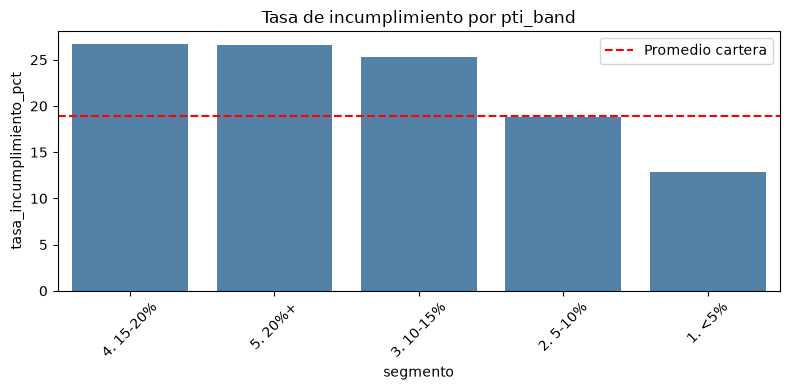

c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,segmento,prestamos,pct_prestamos,resueltos,tasa_incumplimiento_pct,tasa_promedio_pct,lift
0,2. 0.5-1x,56882,21.04,19600,23.60,18.96,1.24
1,3. 1-2x,47575,17.60,16176,19.18,18.96,1.01
2,1. <0.5x,69867,25.85,22834,19.09,18.96,1.01
3,4. 2-4x,72819,26.94,26649,16.38,18.96,0.86
4,5. 4x+,23149,8.56,8961,15.75,18.96,0.83


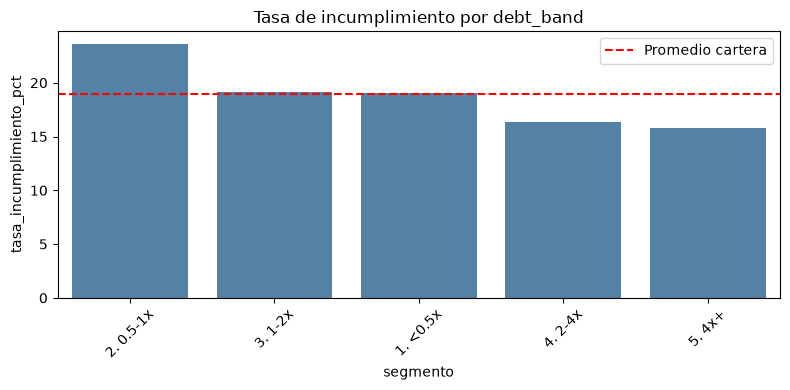

c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,segmento,prestamos,pct_prestamos,resueltos,tasa_incumplimiento_pct,tasa_promedio_pct,lift
0,Sin dato,18745,6.94,5402,24.51,18.96,1.29
1,< 1 year,24650,9.12,7555,20.54,18.96,1.08
2,1 year,17722,6.56,6189,19.87,18.96,1.05
3,8 years,10533,3.90,4313,19.55,18.96,1.03
4,9 years,9045,3.35,3554,19.16,18.96,1.01
5,4 years,16207,6.00,5527,19.05,18.96,1.00
6,3 years,21451,7.94,7475,18.97,18.96,1.00
7,2 years,24036,8.89,8321,18.78,18.96,0.99
8,7 years,10823,4.00,4432,18.68,18.96,0.99
9,6 years,11870,4.39,4323,18.23,18.96,0.96


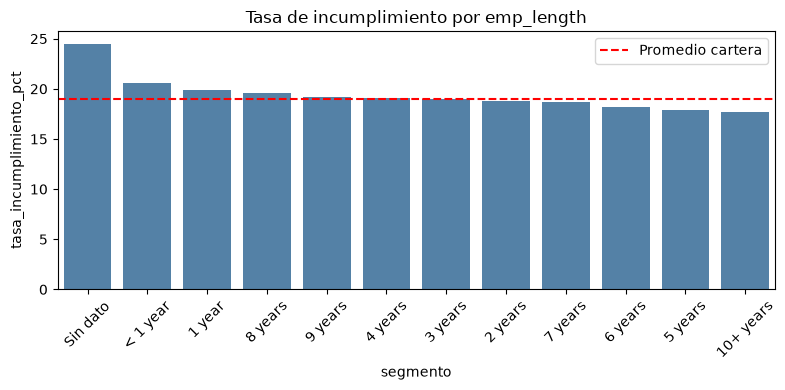

c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,segmento,prestamos,pct_prestamos,resueltos,tasa_incumplimiento_pct,tasa_promedio_pct,lift
0,RENT,105659,39.09,36771,22.28,18.96,1.18
1,OWN,30927,11.44,10243,19.45,18.96,1.03
2,MORTGAGE,133351,49.34,47150,16.28,18.96,0.86
3,OTHER,355,0.13,56,7.14,18.96,0.38


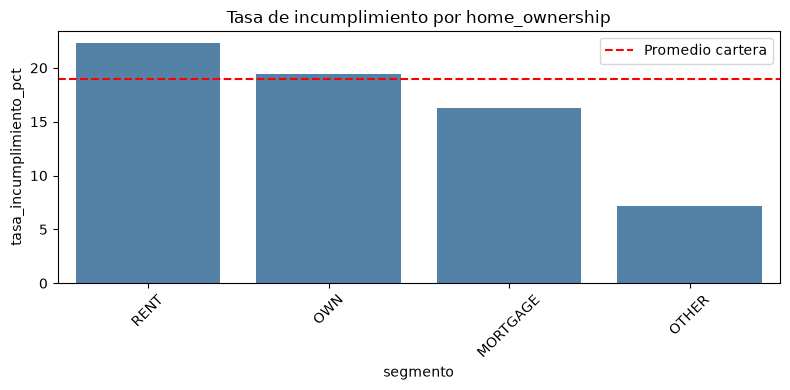

c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,segmento,prestamos,pct_prestamos,resueltos,tasa_incumplimiento_pct,tasa_promedio_pct,lift
0,1. <40k,40172,14.86,14166,22.86,18.96,1.21
1,2. 40k-70k,100817,37.30,36730,20.59,18.96,1.09
2,3. 70k-100k,67099,24.82,23420,17.56,18.96,0.93
3,4. 100k-150k,41630,15.40,13835,15.08,18.96,0.80
4,5. 150k+,20558,7.61,6068,14.19,18.96,0.75
5,Sin dato,16,0.01,1,0.00,18.96,0.00


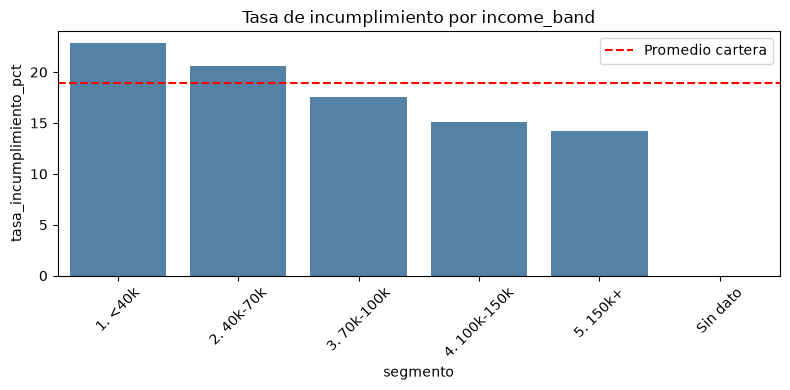

c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,segmento,prestamos,pct_prestamos,resueltos,tasa_incumplimiento_pct,tasa_promedio_pct,lift
0,small_business,2615,0.97,938,27.19,18.96,1.43
1,moving,1744,0.65,687,21.54,18.96,1.14
2,debt_consolidation,152281,56.34,55171,20.26,18.96,1.07
3,medical,3173,1.17,1044,19.73,18.96,1.04
4,other,16278,6.02,5126,19.33,18.96,1.02
5,major_purchase,5584,2.07,1881,17.97,18.96,0.95
6,renewable_energy,156,0.06,63,17.46,18.96,0.92
7,vacation,1863,0.69,625,17.44,18.96,0.92
8,home_improvement,17601,6.51,5918,17.22,18.96,0.91
9,house,1786,0.66,504,16.47,18.96,0.87


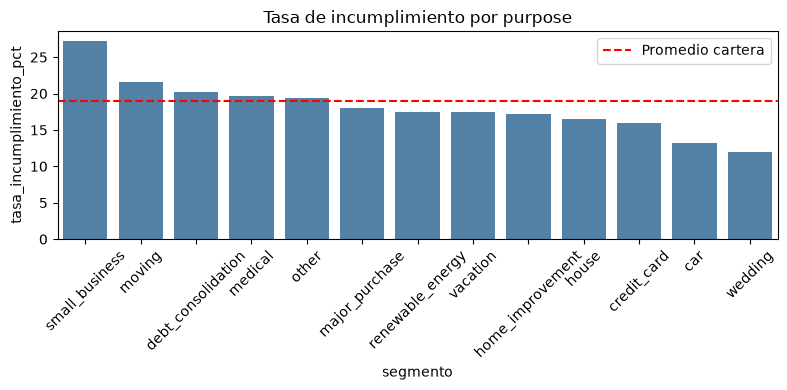

c:\Users\ASUS\Documents\CAMILO ROJAS\Data Analyst\fintech-project\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,segmento,prestamos,pct_prestamos,resueltos,tasa_incumplimiento_pct,tasa_promedio_pct,lift
0,Northeast,55013,20.35,18798,19.89,18.96,1.05
1,South,97680,36.14,33533,19.43,18.96,1.02
2,Midwest,48463,17.93,16413,19.22,18.96,1.01
3,West,69136,25.58,25476,17.49,18.96,0.92


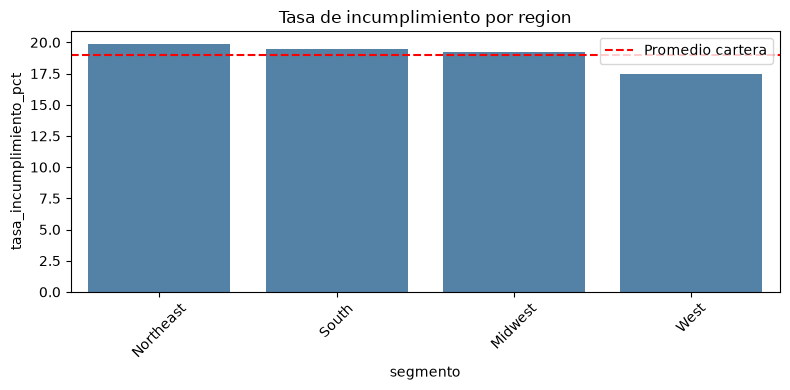

In [45]:
col_segmento = ['pti_band','debt_band', 'emp_length', 'home_ownership', 'income_band', 'purpose', 'region']
riesgo_por_segmento(col_segmento)

Segment findings (lift = how many times more a segment defaults than the 18.96% average):

- **Payment-to-income shows the largest gap.** Default goes from 12.84% when the installment takes less than 5% of income to about 26% from 10% upwards (lift 1.33–1.41).
- **Missing employment length stands out.** The 18,745 customers who didn't report it (about 7% of loans) default 24.51% (lift 1.29), more than any group with data, while employment length itself barely changes the risk (17.70% to 20.54%). Keeping those nulls as their own group (T2) is what makes this visible.
- **Lower income and renting go with higher risk.** Default falls steadily as income rises (22.86% below 40k to 14.19% above 150k), and renters default 22.28% against 16.28% for mortgage holders.
- **Existing debt over income goes the other way** (23.60% at 0.5–1x vs 15.75% at 4x+). This fits with Step 1: the median existing debt is above the median income, so the debt likely includes mortgages.
- **Purpose:** `small_business` defaults 27.19% and `credit_card` refinancing 15.96%, against 20.26% for `debt_consolidation`.
- **Region barely changes the risk** (17.49% in the West to 19.88% in the Northeast).

These gaps are descriptive, one variable at a time, and they show the direction of each relationship. Steps 5.2 and 5.3 measure which ones are strong enough to matter.

### 5.2 Which Categorical Variables Are Related to Default? (P8)

**🎯 What I do and why:** the gaps of 5.1 could be chance, or too small to matter. The **chi-square test of independence** answers the first doubt (H₀: default is independent of the variable; H₁: default depends on it). All it says is whether there's evidence. With about 94,000 resolved loans almost any gap gives p < 0.05, so it can't rank the variables. **Cramér's V** answers the second doubt, and it's the **filter** of this step. Below 0.10 the relationship is very weak, so the variable is treated as independent of default and stops here. From 0.10 up, it moves on to 5.4 and 5.5. The direction of each relationship (which group defaults more) is already in the tables of 5.1.

**The test's assumptions, checked before reading it:**

1. **Independent observations:** each row has to be a different customer who appears only once. Step 1 showed that `customer_id` is unique in both tables and each customer has exactly one loan, so every resolved loan is an independent observation.
2. **Enough expected frequencies:** the test compares the observed counts with the counts expected if there were no relationship. It's only reliable if most cells (at least 80%) have an expected count of 5 or more and none falls below 1. `prueba_chi2` checks this with `expected`, the fourth result of `chi2_contingency`.

💡 This is where bringing data into Python makes sense: the tests need every individual loan, not aggregated groups. I bring only the **resolved** loans, the only ones with a final outcome, and only the columns I'll use. Numeric variables enter through their bands (`pti_band`, `debt_band`, `income_band`), so every variable is categorical and gets tested the same way; 5.3 checks them again with their original values. Grade and term go in as reference points. `nivel_relacion` labels each coefficient with the reading scale, so the label comes from the rule, not from my judgment. The table keeps only what the reading needs: the p-value (is there evidence?), the expected-frequency check (can I trust that p-value?), Cramér's V with its label (how strong?) and whether the variable passes the filter. **What I expect:** grade at the top, payment-to-income as the strongest customer variable, and the assumption met in every table. If a table fails, I deal with its smallest category before reading it.

In [46]:
%%bigquery resueltos
SELECT
    is_default,
    grade,
    term_months,
    int_rate_pct,
    funded_amount,
    ingreso_efectivo,
    payment_to_income,
    loan_to_income,
    debt_to_income,
    pti_band,
    debt_band,
    income_band,
    emp_length,
    home_ownership,
    verification_status,
    purpose,
    region
FROM `fintech-510922.fintech_clean.view_loan`
WHERE is_resolved = 1;   -- solo préstamos con resultado final (pagado o incumplido)

Query is running:   0%|          |

Downloading:   0%|          |

In [47]:
def nivel_relacion(valor): # Clasifica un coeficiente con la escala de lectura (V de Cramér y punto-biserial, en valor absoluto)
    valor = abs(valor) # el signo da la dirección, no la fuerza
    if valor < 0.1:
        return 'Muy débil, sin relación'
    elif valor < 0.3:
        return 'Débil'
    elif valor < 0.5:
        return 'Moderada'
    return 'Fuerte'

def prueba_chi2(df, variable_1, variable_2): # Prueba chi-cuadrado de independencia entre dos variables categóricas: revisa el supuesto de frecuencias esperadas y mide la fuerza con la V de Cramér
    tabla = pd.crosstab(df[variable_1], df[variable_2]) # tabla de contingencia con conteos (la prueba no usa porcentajes)
    chi2_stat, p_value, dof, expected = chi2_contingency(tabla) # estadístico, valor p, grados de libertad y frecuencias esperadas
    pct_esperadas_5 = round((expected >= 5).mean() * 100, 1) # % de celdas con frecuencia esperada de al menos 5
    minimo_esperado = round(expected.min(), 1) # frecuencia esperada más pequeña (nunca debe ser menor a 1)
    n = tabla.to_numpy().sum() # total de observaciones
    k = min(tabla.shape) - 1 # dimensión menor de la tabla, menos 1
    v_cramer = np.sqrt(chi2_stat / (n * k)) # fuerza de la asociación, de 0 a 1
    return {'variable_1': variable_1, 'variable_2': variable_2, 'p_value': p_value,
            'pct_esperadas_5': pct_esperadas_5, 'minimo_esperado': minimo_esperado,
            'supuesto_cumplido': (pct_esperadas_5 >= 80) and (minimo_esperado >= 1), # True: el valor p es confiable
            'v_cramer': round(v_cramer, 3), 'relacion': nivel_relacion(v_cramer)}

,variable_1,variable_2,p_value,pct_esperadas_5,minimo_esperado,supuesto_cumplido,v_cramer,relacion,pasa_filtro
0,grade,is_default,0.000000e+00,100.0,127.2,True,0.265,Débil,True
1,term_months,is_default,0.000000e+00,100.0,4291.1,True,0.179,Débil,True
2,pti_band,is_default,5.335324e-306,100.0,95.4,True,0.123,Débil,True
7,verification_status,is_default,3.166411e-164,100.0,5498.2,True,0.089,"Muy débil, sin relación",False
6,home_ownership,is_default,2.904267e-106,100.0,10.6,True,0.072,"Muy débil, sin relación",False
4,income_band,is_default,4.024624e-97,83.3,0.2,False,0.070,"Muy débil, sin relación",False
3,debt_band,is_default,2.455837e-96,100.0,1698.9,True,0.069,"Muy débil, sin relación",False
8,purpose,is_default,1.164612e-50,100.0,11.9,True,0.053,"Muy débil, sin relación",False
5,emp_length,is_default,2.449481e-29,100.0,673.8,True,0.042,"Muy débil, sin relación",False
9,region,is_default,3.833459e-11,100.0,3111.7,True,0.023,"Muy débil, sin relación",False


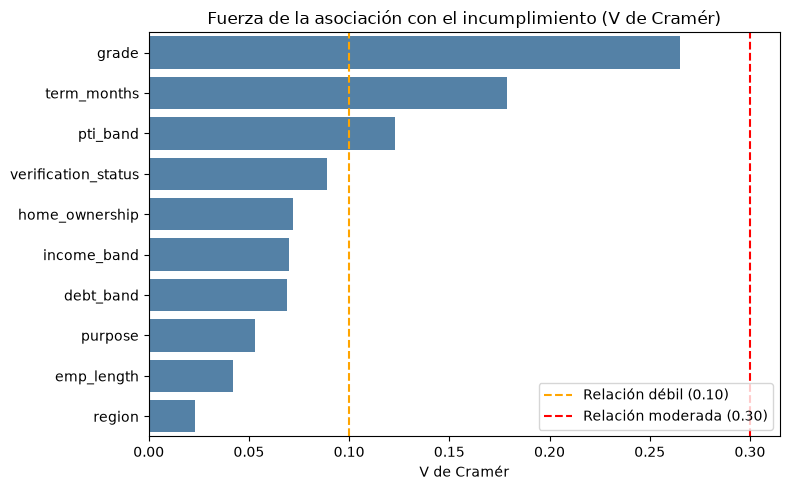

In [48]:
# cada variable frente al incumplimiento, ordenadas por la fuerza de la asociación
alpha = 0.05 # umbral de significancia
variables = ['grade', 'term_months', 'pti_band', 'debt_band', 'income_band', 'emp_length',
             'home_ownership', 'verification_status', 'purpose', 'region']

resultados = []
for variable in variables:
    resultados.append(prueba_chi2(resueltos, variable, 'is_default')) # una fila por variable

asociacion = pd.DataFrame(resultados).sort_values('v_cramer', ascending=False)
asociacion['pasa_filtro'] = asociacion['v_cramer'] >= 0.1 # True: relación al menos débil, sigue al 5.4 y 5.5
display(asociacion)

plt.figure(figsize=(8, 5))
sns.barplot(data=asociacion, y='variable_1', x='v_cramer', color='steelblue')
plt.axvline(0.1, color='orange', linestyle='--', label='Relación débil (0.10)') # por debajo: muy débil, sin relación
plt.axvline(0.3, color='red', linestyle='--', label='Relación moderada (0.30)')
plt.title('Fuerza de la asociación con el incumplimiento (V de Cramér)')
plt.xlabel('V de Cramér')
plt.ylabel('')
plt.legend()
plt.tight_layout()
plt.show()

**Assumption check:** before reading any Cramér’s V, I check that each test is reliable (column `supuesto_cumplido`). This is a different question from the filter: the assumption asks whether the test can be trusted, the filter asks whether the relationship is strong enough to matter. Nine of the ten tables meet the assumption; `income_band` doesn’t. 83.3% of its cells have an expected count of 5 or more, which is enough, but its smallest expected count is 0.2, below the minimum of 1. With a default rate of 18.96%, an expected count of 0.2 means one band holds about one resolved loan (0.2 ÷ 0.1896). A single loan can’t support a test, and merging it into a neighboring band would give it an income it may not have. So I count the loans in each band and repeat the test without the smallest one.

In [49]:
# income_band no cumple el supuesto: se cuentan los préstamos de cada banda y se repite la prueba sin la más pequeña
conteo_ingreso = resueltos['income_band'].value_counts() # préstamos resueltos por banda de ingreso
display(conteo_ingreso)
banda_menor = conteo_ingreso.idxmin() # la banda con menos préstamos
pd.DataFrame([prueba_chi2(resueltos[resueltos['income_band'] != banda_menor], 'income_band', 'is_default')]) # misma prueba sin esa banda

income_band
2. 40k-70k      36730
3. 70k-100k     23420
1. <40k         14166
4. 100k-150k    13835
5. 150k+         6068
Sin dato            1
Name: count, dtype: int64

,variable_1,variable_2,p_value,pct_esperadas_5,minimo_esperado,supuesto_cumplido,v_cramer,relacion
0,income_band,is_default,3.963639e-98,100.0,1150.4,True,0.07,"Muy débil, sin relación"


Findings (all ten variables have p < 0.05, as expected with 94,224 loans, so Cramér's V decides):

- **The assumptions hold.** Every table meets the expected-frequency rule except `income_band`. Without its smallest band it meets the rule too, and V stays at 0.07, so the decision on income doesn't change.
- **Three variables pass the filter, all with a weak relationship:** the **grade** (V 0.27), the **term** (0.18) and **payment-to-income** (0.12), the only customer variable above 0.10. None reaches a moderate relationship (0.30). Default depends on several factors at once, so no single variable separates good and bad payers on its own.
- **Seven variables are treated as independent of default** (below 0.10, very weak): verification 0.09, housing 0.07, income 0.07, existing debt 0.07, purpose 0.05, employment length 0.04 and region 0.02. Their gaps in 5.1 are real, but too small, or they affect too few loans, to separate customers across the portfolio. `Sin dato` in employment length defaults 24.51%, for instance, but it's only 7% of loans. **Decision:** they leave the risk analysis and shouldn't be used as approval or pricing criteria.
- **What moves on:** term and payment-to-income as signals, and the grade as the control of 5.5. Verification comes back in 5.5 for a different reason. It isn't a risk question but a cost one, since the company pays for every verification.

### 5.3 Do the Numeric Variables Confirm the Filter? (P8)

**🎯 What I do and why:** in 5.2 the numeric variables entered through their bands, so their result depends on where I placed the cutoffs. The **point-biserial correlation** measures whether a numeric variable changes between the two groups of a binary variable, here paid (0) and defaulted (1), using the original values. If its strength agrees with the V of the bands, the filter doesn't depend on the cutoffs. I read it with the same scale as Cramér's V, in absolute value. The sign gives the direction: positive means defaulted loans have higher values.

**Its weak spot, and how I handle it:** the point-biserial is a Pearson correlation, so extreme values can pull it. Income has them: Step 2 showed 98% of customers between 16,842 and 278,000, with a maximum of 9.55 million. So I calculate it twice, once with the original values and once with each variable capped at its percentile 99 (`clip`). If both land on the same level, the extremes aren't driving the result. If they don't, I read the capped one.

💡 `pointbiserialr` comes from `scipy.stats` and returns the coefficient and its p-value. Each variable enters without nulls (`dropna`), because the ratios are unknown for customers with implausible income (T2). **What I expect:** payment-to-income above 0.10 and loan-to-income close to it (both divide by income), income negative (more income, less default) and existing debt below 0.10.

In [50]:
# cada variable numérica frente al incumplimiento (0/1): con sus valores originales y recortada en el percentil 99
numericas_riesgo = ['payment_to_income', 'loan_to_income', 'debt_to_income', 'ingreso_efectivo', 'funded_amount', 'int_rate_pct']

filas = []
for variable in numericas_riesgo:
    datos = resueltos[['is_default', variable]].dropna().astype(float) # sin nulos y en float, como pide la prueba
    r, p_value = pointbiserialr(datos['is_default'], datos[variable]) # correlación con los valores originales
    recortada = datos[variable].clip(lower=datos[variable].quantile(0.01)).clip(upper=datos[variable].quantile(0.99)) # valores por encima del percentil 99 llevados al percentil 99
    r_p99, p_p99 = pointbiserialr(datos['is_default'], recortada) # misma prueba sin el peso de los extremos
    filas.append({'variable': variable,
                  'r': round(r, 3), 'p_value': p_value, 'relacion': nivel_relacion(r),
                  'r_p99': round(r_p99, 3), 'relacion_p99': nivel_relacion(r_p99), 'p_value_p99': p_p99,
                  'pasa_filtro': abs(r_p99) >= 0.1}) # True: relación al menos débil

biserial = pd.DataFrame(filas).sort_values('r_p99', key=abs, ascending=False) # de la relación más fuerte a la más débil, sin importar el signo
biserial

,variable,r,p_value,relacion,r_p99,relacion_p99,p_value_p99,pasa_filtro
5,int_rate_pct,0.248,0.000000e+00,Débil,0.250,Débil,0.000000e+00,True
1,loan_to_income,0.146,0.000000e+00,Débil,0.148,Débil,0.000000e+00,True
0,payment_to_income,0.126,0.000000e+00,Débil,0.127,Débil,0.000000e+00,True
3,ingreso_efectivo,-0.040,2.614090e-35,"Muy débil, sin relación",-0.065,"Muy débil, sin relación",1.015363e-88,False
4,funded_amount,0.065,4.291092e-88,"Muy débil, sin relación",0.065,"Muy débil, sin relación",5.423964e-90,False
2,debt_to_income,-0.050,2.928347e-53,"Muy débil, sin relación",-0.051,"Muy débil, sin relación",2.633864e-55,False


Findings (all six have p < 0.05, so the level decides):

- **The filter holds without the bands.** Payment-to-income has a weak relationship with default (0.13), like its band in 5.2 (V 0.12). Income (−0.04) and existing debt (−0.05) are very weak, like their bands (V 0.07 each). The result of 5.2 doesn't depend on where I placed the cutoffs.
- **The extreme values don't change any decision.** Capping at percentile 1 and 99 leaves every variable at the same level. Income moves the most (−0.040 to −0.065): its extreme incomes were diluting the relationship, but it stays very weak. Both negative signs point the same way as the tables of 5.1: more income, slightly less default, and more existing debt, slightly less default.
- **Two more variables pass the filter, and both may repeat something already known.** The rate (0.25) and loan-to-income (0.15) have a weak relationship with default. The rate may just be the price of the grade, and loan-to-income divides by income, as payment-to-income does. 5.4 checks both.
- **The amount lent is very weak** (0.07): the size of the loan doesn't separate good and bad payers on its own.

### 5.4 Which Numeric Variables Say the Same Thing? (P8)

**🎯 What I do and why:** 5.2 and 5.3 left three numeric variables with a weak relationship to default: payment-to-income, loan-to-income and the rate. Before using them, I check whether they repeat information I already have. If two variables say the same thing, a rule that uses both adds nothing and counts the same risk twice (collinearity). Three checks matter for what comes next: whether payment-to-income repeats the grade (if it did, a rule based on it would add nothing), whether it repeats loan-to-income, and whether the rate repeats the grade.

**Why Spearman and not Pearson:** Pearson measures a straight-line relationship with the original values, so a few extreme values can change it completely. These variables have them. Step 1 kept the IQR outliers of amount, rate and installment because they're legitimate loans, and Step 2 showed income at 278,000 in percentile 99 against a maximum of 9.55 million. Spearman works with ranks (the order of the values), so those extremes can't drag it. It also doesn't need a straight line, only that one variable tends to rise or fall with the other.

💡 The grade becomes a number (A = 1 … G = 7) so it can be correlated as an ordered variable. The mask (`np.triu`) hides the upper half of the matrix, which mirrors the lower half. **What I expect:** the rate to repeat the grade (the lender prices by grade), and payment-to-income to repeat loan-to-income, since both divide by income.

In [51]:
# el grado se convierte en número (A=1 ... G=7) para poder correlacionarlo como variable ordenada
resueltos['grade_num'] = resueltos['grade'].map({'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7})

numericas = ['grade_num', 'int_rate_pct', 'term_months', 'funded_amount', 'ingreso_efectivo',
             'payment_to_income', 'loan_to_income', 'debt_to_income']
resueltos[numericas] = resueltos[numericas].astype(float) # BigQuery devuelve tipos nullable; se pasan a float para los cálculos

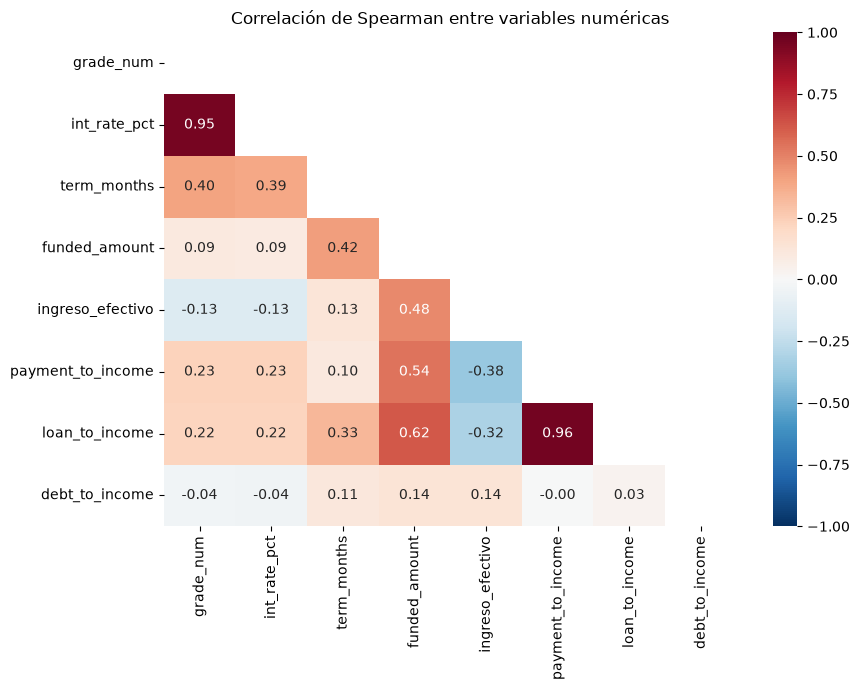

In [52]:
correlacion = resueltos[numericas].corr(method='spearman') # correlación por rangos, resistente a extremos

mascara = np.triu(np.ones_like(correlacion, dtype=bool)) # oculta la mitad superior, que repite la inferior
plt.figure(figsize=(9, 7))
sns.heatmap(correlacion, mask=mascara, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Correlación de Spearman entre variables numéricas')
plt.tight_layout()
plt.show()

Findings:

- **Payment-to-income and loan-to-income repeat each other** (0.96, strong: collinearity), so a rule needs only one. I keep payment-to-income: it's what the customer pays each year, and it's the base of the approval rule (Step 6).
- **The rate repeats the grade** (0.95, strong). The lender prices almost only by grade, so the rate's relationship with default in 5.3 is the grade's, and it doesn't move on as a signal of its own. It also explains why the rate misses risks the grade doesn't see, such as the term (Step 4.2). The grade is the control in 5.5.
- **Payment-to-income has only a weak positive relationship with the grade** (0.23). It doesn't repeat the grade, so it may carry information the grade lacks. A correlation doesn't hold the grade fixed, though, so 5.5 tests it within each grade.
- **Existing debt over income has no relationship, or only a weak one, with any other variable** (−0.04 to 0.14), which fits its very weak V in 5.2.

### 5.5 Do the Signals Hold Within the Same Grade? (K4, K8)

**🎯 What I do and why:** 5.2 to 5.4 left two signals, the term and payment-to-income. Both could still be the grade in disguise. If 60-month or high-installment loans are concentrated in worse grades, their higher default belongs to the grade, and a rule based on them would only repeat it. The weak Spearman of 5.4 suggests that isn't the case, but a correlation doesn't hold the grade fixed. So I compare two groups **within the same grade** with the **two-proportion z-test**. It's the right test here because default is binary (defaulted or not) and I'm comparing two rates. H₀: both groups have the same default rate; H₁: their rates differ.

I only test the comparisons a decision depends on, and I chose them before seeing the results:

| Comparison | Held constant | Question | Decision it supports |
|---|---|---|---|
| Payment-to-income `3. 10-15%` vs `1. <5%` | grade | Does payment-to-income add information the grade doesn't have? | Approval rule (Step 6) |
| Term 60 vs 36 months | grade | Does the 60-month term default more at the same grade? | Term premium, or 60 months only for low-risk grades |
| `verified` vs `not verified` | grade | Does verification reduce default? | Keep, redesign or cut the cost of verifying (K4) |

💡 I read each result with three questions:

1. **Is there evidence of a difference?** The p-value below alpha = 0.05.
2. **Which way does it go, and how big is it?** The difference in points, and its **95% confidence interval**: the range where the real difference plausibly sits. A narrow interval around zero means "no difference". A wide one that crosses zero means "not enough loans to decide". Without the interval, both cases would look the same: a high p-value.
3. **Is it worth acting on?** A significant difference of half a point doesn't justify changing a policy, so the size gets translated into money: the approval rule in Step 6, the term in the margins of Step 4.2, verification in its cost.

**Criterion for a finding:** I run 21 tests (3 comparisons × 7 grades), so at 5% about 1 could come out significant by chance alone. A signal only counts if it points the same way and is significant in most grades. A single grade is never enough. The function skips any grade where a group has fewer than 10 defaults or 10 paid loans, the usual condition for the z-test to be reliable. The table shows the size of each group (`n_a`, `n_b`), because a non-significant result with few loans means "can't decide", not "no difference".

In [53]:
def prueba_z(df, columna, grupo_a, grupo_b, control, objetivo='is_default', minimo=10): # Prueba z de dos proporciones: compara la tasa de incumplimiento de dos grupos dentro de cada nivel de una variable de control
    resultados = []
    for nivel in sorted(df[control].dropna().unique()): # un nivel del control a la vez (por ejemplo, cada grado)
        datos = df[df[control] == nivel] # solo los préstamos de este nivel
        a = datos.loc[datos[columna] == grupo_a, objetivo] # resultados (0 o 1) del grupo A
        if grupo_b == 'resto':
            b = datos.loc[datos[columna] != grupo_a, objetivo] # todos los demás préstamos del nivel
        else:
            b = datos.loc[datos[columna] == grupo_b, objetivo] # resultados (0 o 1) del grupo B

        exitos = [a.sum(), b.sum()] # incumplimientos de cada grupo (suma de unos)
        observaciones = [len(a), len(b)] # préstamos de cada grupo
        if min(exitos[0], observaciones[0] - exitos[0], exitos[1], observaciones[1] - exitos[1]) < minimo:
            continue # se salta el nivel si algún grupo tiene menos de 10 incumplidos o 10 pagados: la prueba no sería confiable

        z_stat, p_value = proportions_ztest(exitos, observaciones) # z_stat no se guarda, el p-valor resume la evidencia
        ic_bajo, ic_alto = confint_proportions_2indep(exitos[0], observaciones[0], exitos[1], observaciones[1], method='wald') # intervalo de confianza del 95 % de la diferencia
        diferencia = exitos[0] / observaciones[0] - exitos[1] / observaciones[1] # tasa del grupo A menos tasa del grupo B

        resultados.append({
            'comparacion': f'{grupo_a} vs {grupo_b}',
            'control': f'{control} = {nivel}',
            'n_a': observaciones[0],
            'n_b': observaciones[1],
            'diferencia_pts': round(diferencia * 100, 2),
            'ic95_bajo': round(ic_bajo * 100, 2),
            'ic95_alto': round(ic_alto * 100, 2),
            'p_value': p_value
        })
    return pd.DataFrame(resultados)

In [54]:
# las comparaciones que sostienen una decisión, definidas antes de ver los resultados
comparaciones = [
    ('pti_band', '3. 10-15%', '1. <5%', 'grade'),
    ('term_months', 60, 36, 'grade'),
    ('verification_status', 'verified', 'not verified', 'grade')
]

tablas = []
for columna, grupo_a, grupo_b, control in comparaciones:
    tablas.append(prueba_z(resueltos, columna, grupo_a, grupo_b, control)) # una tabla por comparación
pruebas = pd.concat(tablas, ignore_index=True) # se apilan en una sola tabla

pruebas['significativa'] = pruebas['p_value'] < alpha # mismo umbral de 0.05 de la prueba chi-cuadrado
print(f"Pruebas significativas: {pruebas['significativa'].sum()} de {len(pruebas)}") # cuántas de las 21 rechazan H0
pruebas

Pruebas significativas: 18 de 21


,comparacion,control,n_a,n_b,diferencia_pts,ic95_bajo,ic95_alto,p_value,significativa
0,3. 10-15% vs 1. <5%,grade = A,2255,6414,1.73,0.58,2.88,1.583437e-03,True
1,3. 10-15% vs 1. <5%,grade = B,4745,8815,3.18,2.02,4.34,2.813798e-08,True
2,3. 10-15% vs 1. <5%,grade = C,5592,7494,7.93,6.53,9.33,1.450840e-29,True
3,3. 10-15% vs 1. <5%,grade = D,3820,3390,12.27,10.23,14.30,3.796729e-31,True
4,3. 10-15% vs 1. <5%,grade = E,2351,980,16.94,13.53,20.35,5.358661e-20,True
5,3. 10-15% vs 1. <5%,grade = F,938,233,14.49,7.61,21.38,7.099917e-05,True
6,3. 10-15% vs 1. <5%,grade = G,323,54,17.75,4.05,31.45,1.570402e-02,True
7,60 vs 36,grade = A,424,16247,3.24,0.50,5.98,4.883896e-03,True
8,60 vs 36,grade = B,3396,23500,4.36,3.06,5.66,4.602496e-13,True
9,60 vs 36,grade = C,7225,19354,7.98,6.82,9.14,6.836177e-46,True


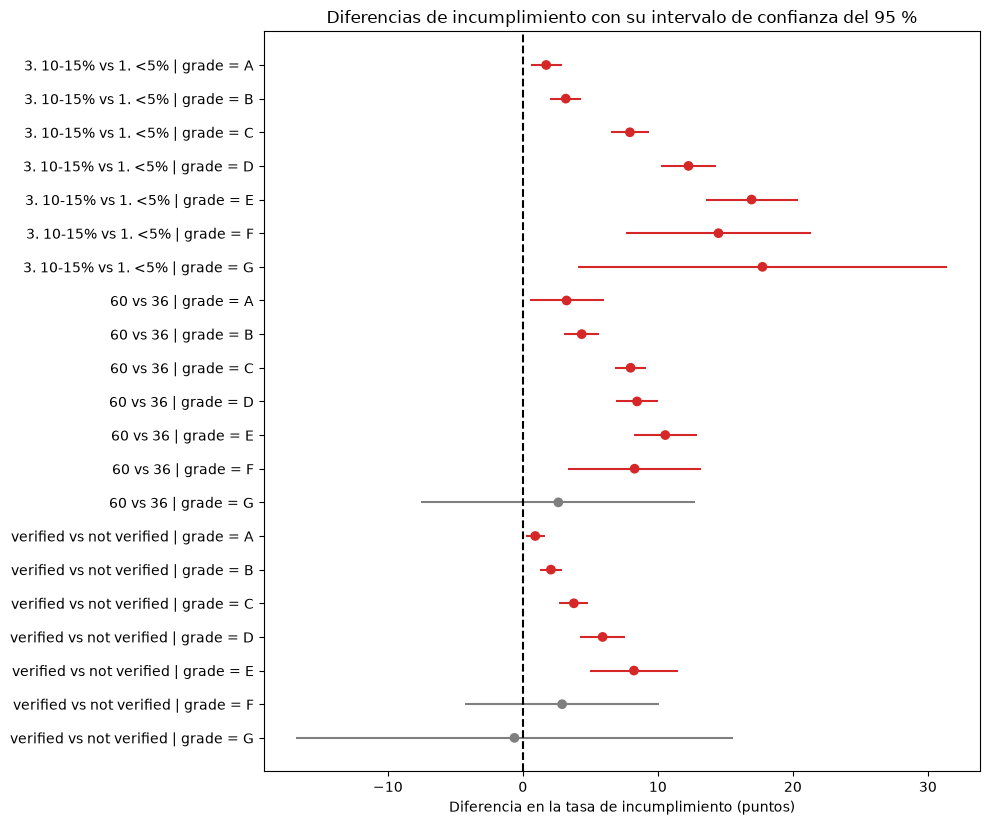

In [55]:
# cada diferencia con su intervalo de confianza: rojo si es significativa, gris si no
posiciones = np.arange(len(pruebas)) # una fila del gráfico por prueba
colores = np.where(pruebas['significativa'], 'tab:red', 'tab:gray')

plt.figure(figsize=(10, len(pruebas) * 0.35 + 1))
plt.hlines(posiciones, pruebas['ic95_bajo'], pruebas['ic95_alto'], colors=colores) # intervalo de confianza del 95 %
plt.scatter(pruebas['diferencia_pts'], posiciones, color=colores, zorder=3) # diferencia observada
plt.axvline(0, color='black', linestyle='--') # cero: sin diferencia
plt.yticks(posiciones, pruebas['comparacion'] + ' | ' + pruebas['control'])
plt.gca().invert_yaxis() # la primera prueba arriba
plt.xlabel('Diferencia en la tasa de incumplimiento (puntos)')
plt.title('Diferencias de incumplimiento con su intervalo de confianza del 95 %')
plt.tight_layout()
plt.show()

Findings (21 tests at alpha = 0.05; 18 are significant, far more than the 1 that chance alone could produce):

- **Payment-to-income holds within every grade.** Moving from `1. <5%` to `3. 10-15%` adds +1.7 points of default in A, +3.2 in B, +7.9 in C, +12.3 in D, +16.9 in E, +14.5 in F and +17.8 in G, all significant. The gap is small in A and grows with the grade. In C and D, where most of the loss is, the intervals are narrow (+6.5 to +9.3 and +10.2 to +14.3). It's a signal of its own, not the grade in disguise, and it's large enough to act on from grade C. Step 6 translates it into money.
- **The 60-month term defaults more in grades A to F:** +3.2 points in A, +4.4 in B, +8.0 in C, +8.5 in D, +10.6 in E and +8.3 in F, all significant. In C and D, where most of the volume is, the intervals are narrow (+6.8 to +9.1 and +6.9 to +10.0). G isn't significant (+2.6, interval −7.5 to +12.8): only 111 of its loans are at 36 months, too few to decide. So the term is a signal of its own, and since Step 4.2 showed that 60 months pays practically the same rate, it's a risk the price doesn't cover.
- **Verified customers default more in grades A to E** (+0.9, +2.1, +3.8, +5.9 and +8.2 points), all significant. F (+2.9, interval −4.3 to +10.1) and G (−0.6, interval −16.8 to +15.6) aren't significant, and their intervals are wide: they only have 200 and 39 non-verified loans, too few to decide. In no grade do verified customers default significantly less. As applied today, the company pays for a process that doesn't reduce default. 5.6 looks at why verified customers default more.

### 5.6 Why Do Verified Customers Default More? (K4, P6)

**🎯 What I do and why:** 5.5 showed that verified customers default more, even within the same grade. The likely explanation is that the lender asks for verification more often on applications it already considers riskier. If so, the share of verified loans should rise from grade A to G. Verification and grade are both categorical, so I use the same chi-square test and Cramér's V of 5.2, plus the table normalized by row to read the direction (% of each verification status within each grade). **What I expect:** a share of verified loans that rises with every grade, and a relationship that's at least weak (V of 0.10 or more).

In [56]:
# ¿se verifica más en los grados riesgosos? (% de cada estado de verificación dentro de cada grado)
display(pd.crosstab(resueltos['grade'], resueltos['verification_status'], normalize='index').round(4) * 100)
pd.DataFrame([prueba_chi2(resueltos, 'grade', 'verification_status')])

verification_status,not verified,verified
grade,,
A,45.03,54.97
B,36.06,63.94
C,27.29,72.71
D,23.31,76.69
E,13.88,86.12
F,8.91,91.09
G,5.81,94.19


,variable_1,variable_2,p_value,pct_esperadas_5,minimo_esperado,supuesto_cumplido,v_cramer,relacion
0,grade,verification_status,0.0,100.0,206.5,True,0.208,Débil


Finding: **verification follows the grade.** The share of verified loans rises at every step, from 55.0% in A to 94.2% in G (V 0.21, weak relationship). The lender verifies the applications it already considers riskier, which is why verified customers default more without verification causing it. That explains the gap across grades. It doesn't explain why verified customers still default more within the same grade (5.5). The lender may also pick the riskier applications inside each grade, but the data can't confirm that without knowing what triggers a verification request.

---

## 🔹 Step 6: Simulate an Approval Rule (P3)

**🎯 My objective:** Estimate what the lender would gain by rejecting applications whose installment takes too much of the customer's income.

💡 First I summarize the resolved loans by payment-to-income band in `cte_tramos`. Then I go through the bands from highest to lowest and accumulate with `SUM(...) OVER acumulado`, a named window defined with `WINDOW`. Each row answers "what if I reject from this band upwards?", weighing the loss avoided against the interest given up. A second CTE, `cte_simulacion`, holds that result, so the final `SELECT` can compare each cutoff with the best one (`pct_del_mejor_beneficio`); a window can't be nested inside another window in the same `SELECT`.

In [57]:
%%bigquery
WITH
cte_tramos AS (
    SELECT
        pti_band,
        COUNT(*) AS prestamos,
        SUM(loss_upper_bound) AS perdida,
        SUM(IF(status_group = 'Pagado', contractual_interest, 0)) AS interes
    FROM `fintech-510922.fintech_clean.view_loan`
    WHERE is_resolved = 1 AND pti_band != 'Sin dato'
    GROUP BY pti_band
),
cte_simulacion AS (
    SELECT
        pti_band AS rechazar_desde_tramo,
        SUM(prestamos) OVER acumulado AS prestamos_rechazados,
        ROUND(SAFE_DIVIDE(SUM(prestamos) OVER acumulado, SUM(prestamos) OVER ()) * 100, 2) AS pct_cartera_rechazada,
        ROUND(SUM(perdida) OVER acumulado, 2) AS perdida_evitada,
        ROUND(SUM(interes) OVER acumulado, 2) AS interes_perdido,
        ROUND(SUM(perdida) OVER acumulado - SUM(interes) OVER acumulado, 2) AS beneficio_neto
    FROM cte_tramos
    -- ventana con nombre: del tramo más alto al más bajo, acumulando fila por fila
    WINDOW acumulado AS (ORDER BY pti_band DESC ROWS UNBOUNDED PRECEDING)
)
SELECT
    *,
    ROUND(SAFE_DIVIDE(beneficio_neto, MAX(beneficio_neto) OVER ()) * 100, 2) AS pct_del_mejor_beneficio -- qué parte del mejor corte captura cada corte
FROM cte_simulacion
ORDER BY rechazar_desde_tramo DESC;

Query is running:   0%|          |

Downloading:   0%|          |

,rechazar_desde_tramo,prestamos_rechazados,pct_cartera_rechazada,perdida_evitada,interes_perdido,beneficio_neto,pct_del_mejor_beneficio
0,5. 20%+,503,0.53,2984525.0,2.635028e+06,349496.75,2.28
1,4. 15-20%,5772,6.13,30977225.0,2.510777e+07,5869457.32,38.34
2,3. 10-15%,25796,27.38,127237225.0,1.119285e+08,15308766.14,100.00
3,2. 5-10%,66840,70.94,246827250.0,2.488893e+08,-2062036.19,-13.47
4,1. <5%,94220,100.00,279669425.0,2.975276e+08,-17858202.90,-116.65


The best cutoff is 10%. Rejecting from that band upwards would have avoided 127.2 million in loss and given up 111.9 million in interest, a **net benefit of +15.3 million**, but it means rejecting 27.4% of the loans. A 15% cutoff gains +5.9 million, almost 40% of the best benefit, and rejects only 6.1%. Below 10% the rule loses money, because it mostly rejects good payers. The benefit carries two biases that pull in opposite directions (the loss is an upper bound; the interest assumes full payment), and the simulation only sees approved applications.

---

## 🔹 Step 7: Evaluate Growth and Quality by Vintage (P5)

**🎯 My objective:** Find out whether the portfolio grows with healthy loans.

💡 `LAG(monto) OVER (ORDER BY issue_year)` brings the previous year's amount into each row, so I can calculate growth without joining the table to itself. I also show `pct_aun_activo`, because in recent years the default rate isn't final yet.

In [58]:
%%bigquery cosechas
WITH
cte_cosechas AS (
    SELECT
        issue_year,
        COUNT(*) AS prestamos,
        SUM(funded_amount) AS monto,
        SUM(is_default) AS incumplidos,
        SUM(is_resolved) AS resueltos,
        SUM(is_active) AS activos
    FROM `fintech-510922.fintech_clean.view_loan`
    GROUP BY issue_year
)
SELECT
    issue_year,
    prestamos,
    ROUND(monto, 2) AS monto,
    ROUND(SAFE_DIVIDE(monto - LAG(monto) OVER (ORDER BY issue_year),
                      LAG(monto) OVER (ORDER BY issue_year)) * 100, 2) AS crecimiento_anual_pct,
    ROUND(SAFE_DIVIDE(incumplidos, resueltos) * 100, 2) AS tasa_incumplimiento_pct,
    ROUND(SAFE_DIVIDE(activos, prestamos) * 100, 2) AS pct_aun_activo
FROM cte_cosechas
ORDER BY issue_year;

Query is running:   0%|          |

Downloading:   0%|          |

In [59]:
cosechas

,issue_year,prestamos,monto,crecimiento_anual_pct,tasa_incumplimiento_pct,pct_aun_activo
0,2012,2594,35467575.0,NaN,15.63,4.32
1,2013,13460,199362825.0,462.10,15.93,8.68
2,2014,23451,348257500.0,74.69,22.42,35.02
3,2015,41916,639403775.0,83.60,20.22,10.04
4,2016,43368,638631475.0,-0.12,18.59,86.08
5,2017,44434,660666350.0,3.45,19.80,72.41
6,2018,49332,791869100.0,19.86,8.72,92.58
7,2019,51737,852355425.0,7.64,13.35,91.21


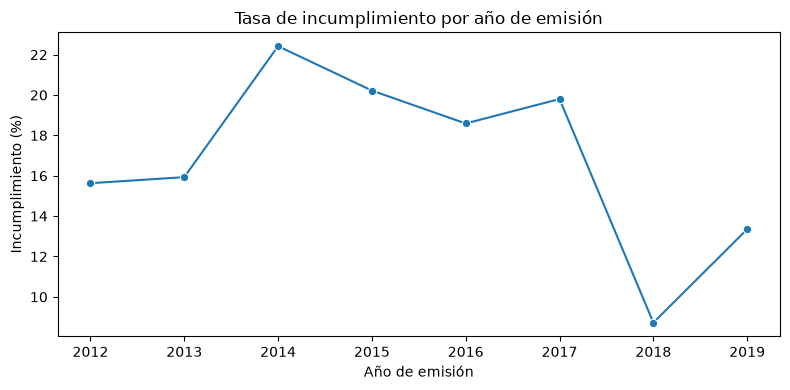

In [60]:
# se observa la evolución del incumplimiento por cosecha
plt.figure(figsize=(8, 4))
sns.lineplot(data=cosechas, x='issue_year', y='tasa_incumplimiento_pct', marker='o')
plt.title('Tasa de incumplimiento por año de emisión')
plt.xlabel('Año de emisión')
plt.ylabel('Incumplimiento (%)')
plt.tight_layout()
plt.show()

Between 2013 and 2015 the amount lent went from 199 to 639 million, and in those same years default rose from 15.93% to 22.42% (2014) and 20.22% (2015). **The fastest growth came with the worst quality.** Growth then stalled (−0.13% in 2016, +3.45% in 2017) and picked up again in 2018 (+19.86%). From 2016 onwards, 72% to 93% of each vintage is still active, so their rates can't be compared yet. The 8.72% of 2018 isn't an improvement: most of those loans haven't had time to default. One anomaly needs a look: the 2014 vintage has 35% active loans and 2015 only 10%, when the more recent vintage should have more.

---

## 🔹 Step 8: Focus Collections (P7)

**🎯 My objective:** Decide where the collections team should start.

💡 I rank the region-grade segments by money in delinquency with `RANK()`, and add each segment's share of the total and the cumulative share (`SUM(...) OVER (ORDER BY ... ROWS UNBOUNDED PRECEDING)`). That's a Pareto analysis. `SUM(...) OVER ()` without an order also repeats the portfolio totals (late loans and late money) in every row.

In [61]:
%%bigquery
WITH
cte_mora AS (
    SELECT
        region,
        grade,
        SUM(is_delinquent) AS prestamos_en_mora,
        SUM(funded_amount * is_delinquent) AS monto_en_mora
    FROM `fintech-510922.fintech_clean.view_loan`
    WHERE is_active = 1
    GROUP BY region, grade
    HAVING SUM(is_delinquent) > 0
)
SELECT
    region,
    grade,
    prestamos_en_mora,
    ROUND(monto_en_mora, 2) AS monto_en_mora,
    SUM(prestamos_en_mora) OVER () AS total_prestamos_mora, -- total de toda la cartera activa, repetido en cada fila
    ROUND(SUM(monto_en_mora) OVER (), 2) AS total_monto_mora,
    RANK() OVER (ORDER BY monto_en_mora DESC) AS ranking,
    ROUND(monto_en_mora
        / SUM(monto_en_mora) OVER () * 100, 2) AS pct_del_total,
    ROUND(SUM(monto_en_mora) OVER (ORDER BY monto_en_mora DESC ROWS UNBOUNDED PRECEDING)
        / SUM(monto_en_mora) OVER () * 100, 2) AS pct_acumulado
FROM cte_mora
ORDER BY ranking;

Query is running:   0%|          |

Downloading:   0%|          |

,region,grade,prestamos_en_mora,monto_en_mora,total_prestamos_mora,total_monto_mora,ranking,pct_del_total,pct_acumulado
0,South,C,662,10617075.0,5614,93449575.0,1,11.36,11.36
1,South,D,518,9186925.0,5614,93449575.0,2,9.83,21.19
2,West,C,450,7615550.0,5614,93449575.0,3,8.15,29.34
3,South,B,440,6806325.0,5614,93449575.0,4,7.28,36.62
4,Northeast,C,392,6333375.0,5614,93449575.0,5,6.78,43.40
5,West,D,339,6088550.0,5614,93449575.0,6,6.52,49.92
6,Midwest,C,319,4916325.0,5614,93449575.0,7,5.26,55.18
7,West,B,295,4431200.0,5614,93449575.0,8,4.74,59.92
8,Northeast,B,277,4238350.0,5614,93449575.0,9,4.54,64.46
9,Northeast,D,263,4219425.0,5614,93449575.0,10,4.52,68.97


About 93 million (by amount lent) sits in 5,614 late loans. **13 of the 28 region-grade segments hold 80% of it**, and the first five hold 43.4%: South C (11.36%), South D (9.83%), West C (8.15%), South B (7.28%) and Northeast C (6.78%). The South appears in three of the top four, and grades B, C and D dominate because of their volume.

---

# EXECUTIVE SUMMARY

**1. The portfolio makes money, but by a margin that a single point of default can erase**

**Context**

I measure the baseline of the whole portfolio: 270,292 loans and 4,166 million lent between 2012 and 2019 (after excluding 7 inconsistent records). Then I compare the interest earned on paid loans with the money lost on defaulted ones.

**Finding**

Of the 94,224 loans that have already ended, 17,863 defaulted. That's a default rate of **18.96%**, almost one in five. Paid loans generated 297.5 million in interest, and defaulted loans represent up to 279.7 million in loss. The gross margin left is only **17.8 million, 6% of the interest earned**, and that's before funding, operating and collection costs. Each defaulted loan costs 15,658 on average, so one extra point of default (about 942 more defaults) would cost around 14.8 million, almost the entire margin.

**Implication**

Problem: profitability depends on default far more than on volume. Solution: **Risk and Finance leadership** should set a portfolio default ceiling below the current 18.96% for the next planning cycle and review it every month next to origination volume. That way, no growth gets approved without its expected default. Findings 2 and 3 show where the reduction can come from.

**2. Pricing doesn't follow risk: grades E to G and the 60-month term are underpriced, and C and D concentrate the loss**

**Context**

For each grade and term I compare the average interest rate, the default rate and the risk-adjusted margin (interest earned minus maximum loss). I also measure how strongly the term is associated with default (chi-square and Cramér's V) and test whether 60-month loans default more within the same grade (two-proportion z-test).

**Finding**

Grades E, F and G are 18,640 loans (6.9% of the portfolio) but explain **26% of the loss**, and all six of their grade-term combinations have negative margins (**−12.0 million**). Default rises much faster than the price: from A to G at 36 months, the rate goes from 7.19% to 29.11%, while default goes from 5.72% to 45.95%. Grades C and D hold 42.4% of the loans and **52.7% of the loss**. At 36 months both already lose money (−1.6 million in C and −5.0 million in D), while A and B generate +28.8 million and subsidize the rest. The term isn't priced either. The 60-month loans (29.8% of the portfolio) pay practically the same rate as the 36-month ones, but within the same grade they default **3.2 to 10.6 points more** in grades A to F, all statistically significant. After the grade, the term is the variable most associated with default (Cramér's V 0.18, weak).

**Implication**

Problem: the riskiest grades and the long term are charged less than they cost. Solution:
- The **Credit Committee** should decide whether to keep originating grades F and G (40% to 49% default) and set a minimum rate for grade E that covers its default.
- The **Pricing team** should calculate the break-even rate for each grade and term, starting with D at 36 months, the largest single loss outside E to G. It should also add a term premium sized to the extra default at 60 months. Because of their volume, a small adjustment in C and D recovers more money than any change in E to G.
- Until that premium exists, **Credit Policy** should offer 60 months only to grades A and B.

**3. The installment's share of income is the strongest customer signal, and it adds information the grade doesn't have**

**Context**

I measure default by payment-to-income band (annual installment divided by income) and test how strongly each variable is associated with default: chi-square and Cramér's V for the bands, point-biserial for the original values. Then I check which variables repeat each other (Spearman), compare payment-to-income within each grade (two-proportion z-test) and simulate rejecting applications from each band upwards.

**Finding**

Default goes from **12.84%** when the installment takes less than 5% of income to **about 26%** from 10% upwards. It's the customer variable most associated with default: Cramér's V 0.12 and point-biserial 0.13, both weak, but it's the only customer variable above 0.10 (every other one is at 0.09 or less). It isn't the grade in disguise either. Its relationship with the grade is weak (Spearman 0.23), and within the same grade, moving from below 5% to 10–15% adds +1.7 points of default in A, +3.2 in B, +7.9 in C, +12.3 in D, +16.9 in E and +14.5 in F, all statistically significant. Loan-to-income carries the same information (Spearman 0.96), so a rule needs only one of the two. Rejecting from 10% would have avoided 127.2 million in loss and given up 111.9 million in interest, a net benefit of **+15.3 million**, but at the cost of rejecting 27.4% of approvals. A 15% cutoff gains **+5.9 million** and rejects only 6.1%.

**Implication**

Problem: customers whose installment takes a large share of their income default much more, in every grade, and the current policy doesn't use it. Solution:
- The **Credit Risk team** should add payment-to-income as a rule on top of the grade: automatic rejection from 15%. It captures almost 40% of the benefit with minimal impact on volume.
- Between 10% and 15%, the **Commercial team** should offer a lower amount until the installment falls below 10% of income, without extending the term (finding 2 shows that longer terms default more).
- The rule should start in grades C to F, where the gap is largest (+7.9 to +16.9 points) and where most of the loss is. In A the gap is under 2 points, which doesn't justify it.
- **Credit Risk and the Data team** should run it as a pilot on a random share of applications and compare its default with the current policy, because this simulation only includes customers who were already approved.

**4. Six customer variables show no relationship with default and shouldn't be used as approval criteria**

**Context**

I test each customer variable's relationship with default: chi-square and Cramér's V for the categorical variables and the bands, and the point-biserial correlation for the original numeric values. Below 0.10 the relationship is very weak, so I treat the variable as independent of default.

**Finding**

Employment length (Cramér's V 0.04), housing (0.07), income (0.07), existing debt (0.07), purpose (0.05) and region (0.02) are all below 0.10. With their original values, income (−0.07 once its extremes are capped) and existing debt (−0.05) stay below 0.10 too. Their gaps do exist in the tables: small business defaults 27.19%, customers who don't report employment length 24.51%, and renters 22.28% against 16.28% for mortgage holders. But they're too small, or they affect too few loans, to separate good and bad payers across the portfolio. Customers without employment length, for example, are only 7% of loans. Existing debt even goes the other way (more debt, less default), which fits a debt figure that includes mortgages: its median (80,455) is higher than the median income (66,000).

**Implication**

Problem: a rule built on these variables would reject or price customers using differences that don't separate risk. Solution:
- The **Credit Risk team** shouldn't add employment length, housing, income, purpose or region as approval or pricing criteria. The grade and payment-to-income (finding 3) already carry the risk signal.
- The **Pricing team** shouldn't price loan purposes differently, small business included.
- The **Data team** should separate mortgage debt from consumer debt and test the debt ratio again, since today it mixes both.

**5. Income verification is concentrated on riskier applicants, but it isn't reducing their default**

**Context**

I compare the share of verified loans in each grade (chi-square and Cramér's V), the default of verified and non-verified customers within each grade (z-test) and verification's own association with default.

**Finding**

Verification rises with risk. It covers 55.0% of grade A loans and 94.2% of grade G (Cramér's V 0.21, weak), which shows the lender asks for it more on the applications it already considers riskier. But even within the same grade, **verified customers default more**: from +0.9 points in A to +8.2 in E, all statistically significant. In F and G the difference isn't significant, because there are only 200 and 39 non-verified loans. In no grade do verified customers default significantly less. Verification's own association with default is very weak (Cramér's V 0.09), and it's applied to 63.8% of loans (Source Verified 38.98% plus Verified 24.82%, Step 1).

**Implication**

Problem: the company pays for a process that, as it's applied today, shows no effect on default. Solution:
- The **Operations team** should review what triggers a verification request, since today it mostly follows the grade.
- **Operations and Credit Risk** should measure its real effect with a controlled test: within the same grade, verify a random group of applications and not another, then compare their default after 6 to 12 months. With that result, the company can decide whether to keep the process, redesign it or cut its cost.

**6. Fast growth came with worse quality, and the late money is concentrated in 13 segments**

**Context**

I compare the amount lent and the default rate by vintage (the year the loan was issued), and rank the 28 region-grade segments by the money in late loans (Pareto analysis).

**Finding**

Between 2013 and 2015 the amount lent went **from 199 to 639 million**, and in those same years default rose from 15.93% to **22.42%** (2014) and 20.22% (2015). Growth picked up again in 2018 (+19.86%), but from 2016 onwards 72% to 93% of each vintage is still active, so their low default rates aren't final yet. Among active loans, about 93 million sits in 5,614 late loans, and **13 of the 28 segments hold 80% of that money**. The top five hold 43.4%, led by South C (11.36%) and South D (9.83%).

**Implication**

Problem: quality is measured too late, and collections effort isn't targeted. Solution:
- The **Risk team** should add early delinquency at 3, 6 and 12 months by vintage to the monitoring dashboard, with an alert when a new vintage performs worse than the previous one at the same age.
- The **Data team** should find out why the 2014 vintage has 35% active loans and 2015 only 10%, when the more recent vintage should have more.
- The **Collections manager** should assign the team's capacity starting with the 13 top segments, beginning with South C and South D (more than a fifth of the late money), and track their recovery every month in the Looker dashboard.

**Personal reflection**

- How much of the benefit of stopping grades F and G overlaps with the payment-to-income rule? Many E to G loans may also have a high payment-to-income, so the two measures could be hitting the same loans.
- Verification covers 94% of grade G loans and changes nothing in their default. What is the process actually checking, and could that budget do more in collections?
- What additional data would I need before presenting the approval rule to the Credit Committee as final: payment history, rejected applications, or both?

**LIMITATIONS**

- **Loss and interest are estimates, not real amounts.** The dataset has no payment or recovery history. The loss of each defaulted loan is counted as its full amount (279.7 million in total), although part was probably repaid or recovered, so the real loss is lower. Interest is contractual (installment × term − amount), which assumes every installment was paid. For loans repaid early, especially at 60 months, the real interest is lower. The true margin could be higher or lower than 17.8 million.
- **A single snapshot without an as-of date.** Each loan only has its current status. Vintages from 2016 onwards are still 72% to 93% active, so their default rates aren't final and vintage curves can't be built.
- **Only approved loans.** Rejected applications aren't available. The approval rule simulation (+15.3 million) assumes that customers who would have been rejected behave like those already approved in the same band.
- **No credit bureau data, costs or balances.** Without a credit score the grade is a black box: "adds information beyond the grade" means beyond the grade as the lender built it. Without costs the margin is gross, and delinquency is measured with the amount lent (about 93 million), not the balance still owed.
- **Association, not cause.** Every test shows that two variables move together, not that one causes the other. Verification shows why this matters: its gap across grades follows the grade.
- **Significance isn't strength.** With 94,224 loans the chi-square is significant for every variable, so Cramér's V, not the p-value, decides which variables matter. The 0.10 threshold is also a convention: a variable just below it isn't proven irrelevant, only too weak to use on its own. With 21 z-tests at alpha = 0.05, about 1 could be significant by chance alone, so a finding requires the same direction in most grades. In grades F and G the groups are small and the intervals wide. They rule out large gaps, not moderate ones.
- **Two variables at a time.** Chi-square, the point-biserial, Spearman and the z-test compare variables in pairs or with one variable held constant. None of them measures the effect of each variable with all the others held constant. The point-biserial is also sensitive to extreme values, which is why I calculate it with each variable capped at its percentile 99.
- **Data quality.** 7 loans with installments that don't cover the amount lent were excluded, incomes below 1,000 per year were treated as unknown, and the column definitions are inferred from a demo dataset similar to LendingClub, without an official data dictionary.

**NEXT STEPS**

With the current data:

- **A logistic regression of default.** *Why:* every test so far looks at two variables at a time, but they act together, and the grade moves with almost everything. *What:* model the probability of default with grade, term and payment-to-income, plus the variables discarded in Step 5.2 to confirm they still add nothing with the others held constant. Train it on 70% of resolved loans and test it on the other 30%. *What I'd get:* the effect of each variable with all the others held constant (odds ratios), which confirms or rejects the approval rule; how much the F/G decision and the payment-to-income rule overlap; and a default probability per customer, the base of a credit scorecard.
- **Separate `Verified` and `Source Verified`.** *Why:* T2 merged them, and verifying the amount with documents is a stronger check than verifying the source. *What I'd get:* whether either kind of verification reduces default within the same grade.

With additional data:

- **Payments and recoveries:** the real loss and margin of each segment, instead of upper bounds.
- **Status history with dates:** vintage curves (default at 3, 6 and 12 months) and early warnings for new vintages.
- **Rejected applications:** the effect of the full approval policy, not only of a rule tested on approved customers.
- **Credit bureau data:** whether the grade can be improved, and what payment-to-income adds to a credit score.
- **Costs:** the net margin and the minimum profitable rate for each grade and term.
- **A pilot of the approval rule:** apply the 15% cutoff and the amount reduction between 10% and 15% to a random share of new applications, and compare their default with the rest after 6 to 12 months. It's the only way to measure the rule's real effect.

---

## 🔹 Step 9: Communicate the Results (Looker Studio / Data Studio Dashboard)

🎯 **My objective**:
Build a five-page dashboard that shows the portfolio KPIs, the risk segments, the approval rule, verification and the collections priorities, with a short text over each chart that says what the data shows.

Looker Studio (renamed Data Studio in April 2026) connects straight to BigQuery, so there's no CSV to export. Most charts read the view `view_loan` and aggregate it themselves, which lets the filters work. Two results can't be rebuilt by simple aggregation, because they accumulate row by row: the approval-rule simulation (Step 6) and the collections Pareto (Step 8). I save those two queries as views, so the dashboard shows exactly the numbers of this notebook.

💡 `CREATE OR REPLACE VIEW` saves the Step 6 query as `dash_regla_aprobacion`. It's the same SQL; only the first line changes. A view stores the query, not the result, so it always reads the current clean data.

In [62]:
%%bigquery
CREATE OR REPLACE VIEW `fintech-510922.fintech_clean.dash_regla_aprobacion` AS
WITH
cte_tramos AS (
    SELECT
        pti_band,
        COUNT(*) AS prestamos,
        SUM(loss_upper_bound) AS perdida,
        SUM(IF(status_group = 'Pagado', contractual_interest, 0)) AS interes
    FROM `fintech-510922.fintech_clean.view_loan`
    WHERE is_resolved = 1 AND pti_band != 'Sin dato'
    GROUP BY pti_band
),
cte_simulacion AS (
    SELECT
        pti_band AS rechazar_desde_tramo,
        SUM(prestamos) OVER acumulado AS prestamos_rechazados,
        ROUND(SAFE_DIVIDE(SUM(prestamos) OVER acumulado, SUM(prestamos) OVER ()) * 100, 2) AS pct_cartera_rechazada,
        ROUND(SUM(perdida) OVER acumulado, 2) AS perdida_evitada,
        ROUND(SUM(interes) OVER acumulado, 2) AS interes_perdido,
        ROUND(SUM(perdida) OVER acumulado - SUM(interes) OVER acumulado, 2) AS beneficio_neto
    FROM cte_tramos
    WINDOW acumulado AS (ORDER BY pti_band DESC ROWS UNBOUNDED PRECEDING) -- del tramo más alto al más bajo
)
SELECT
    *,
    ROUND(SAFE_DIVIDE(beneficio_neto, MAX(beneficio_neto) OVER ()) * 100, 2) AS pct_del_mejor_beneficio
FROM cte_simulacion;

Query is running:   0%|          |

""


💡 Same idea with the Step 8 query, saved as `dash_cobranza`. It adds one column, `segmento` (region and grade in one label, such as `South C`), because a chart needs a single dimension to name each bar.

In [63]:
%%bigquery
CREATE OR REPLACE VIEW `fintech-510922.fintech_clean.dash_cobranza` AS
WITH
cte_mora AS (
    SELECT
        region,
        grade,
        SUM(is_delinquent) AS prestamos_en_mora,
        SUM(funded_amount * is_delinquent) AS monto_en_mora
    FROM `fintech-510922.fintech_clean.view_loan`
    WHERE is_active = 1
    GROUP BY region, grade
    HAVING SUM(is_delinquent) > 0
)
SELECT
    CONCAT(region, ' ', grade) AS segmento, -- etiqueta única por barra, por ejemplo 'South C'
    region,
    grade,
    prestamos_en_mora,
    ROUND(monto_en_mora, 2) AS monto_en_mora,
    RANK() OVER (ORDER BY monto_en_mora DESC) AS ranking,
    ROUND(monto_en_mora / SUM(monto_en_mora) OVER () * 100, 2) AS pct_del_total,
    ROUND(SUM(monto_en_mora) OVER (ORDER BY monto_en_mora DESC ROWS UNBOUNDED PRECEDING)
        / SUM(monto_en_mora) OVER () * 100, 2) AS pct_acumulado
FROM cte_mora;

Query is running:   0%|          |

""
